# SportSnap: Phân loại Môn Thể thao qua Hình ảnh bằng CNN (Transfer Learning)

**Đề tài số 16 — Thị giác máy tính (IUH)**
GVHD: Lê Thị Vĩnh Thanh

**Mục tiêu:**
1. Xây dựng mô hình phân loại môn thể thao qua ảnh (15–20 môn phổ biến), Accuracy ≥ 0.88 trên tập test.
2. Dùng bộ dữ liệu Sports Image Classification (Kaggle, công khai).
3. So sánh ≥ 3 kiến trúc: **CNN từ đầu (baseline)**, **MobileNetV2** (transfer learning), **ResNet** (transfer learning).
4. Phân tích Grad-CAM để xác định vùng ảnh quan trọng (đặc trưng thị giác: màu sân, trang phục, dụng cụ...) đóng góp vào quyết định phân loại.

**Bộ dữ liệu:** [Sports Image Classification — Kaggle](https://www.kaggle.com/code/prathmesh284/image-classification-sports/input?select=valid)
(cấu trúc thư mục dạng `train/ valid(hoặc test)/` mỗi thư mục con là 1 lớp môn thể thao)

> **Lưu ý:** Notebook này được thiết kế để chạy trên **Kaggle Notebook**, **Google Colab** hoặc **máy cục bộ (Windows/Linux)**. Trên Kaggle, chỉ cần "Add Data" bộ dữ liệu trên, dữ liệu sẽ nằm ở `/kaggle/input/...`. Trên Colab, tải dữ liệu bằng Kaggle API rồi chỉnh biến `DATA_ROOT` bên dưới.
> Vì Kaggle không có sẵn kiến trúc "ResNet18" trong `tf.keras.applications`, nhóm dùng **ResNet50** (Keras) làm đại diện họ ResNet — có thể đổi sang `torchvision.models.resnet18` (PyTorch) nếu muốn bám sát đúng ResNet18.

---
### Các cải tiến & phần gộp (từ `SportSnap_Training_Optimized` + `detainhom_bosung`)
1. **Hàm huấn luyện dùng chung** `train_transfer_model()` (head → fine-tune), thay cho 2 cell lặp code; dùng lại được cho K-Fold và Multi-seed.
2. **Label smoothing 0.1** (loss `CategoricalCrossentropy`) – giảm quá tự tin, giúp chịu nhiễu nhãn (ví dụ `figure skating pairs` ↔ `women`).
3. **Cosine LR decay** ở giai đoạn fine-tune (thay cho ReduceLROnPlateau), và **EarlyStopping/Checkpoint theo `val_loss`** (chọn epoch theo `val_loss` ổn định hơn `val_accuracy` khi accuracy dễ bão hòa).
4. **CNN từ đầu** thêm BatchNorm + block conv kép → baseline mạnh hơn, so sánh công bằng hơn.
5. **Test-Time Augmentation (lật ngang)** khi đánh giá + ensemble có trọng số.
6. **So sánh Frozen vs Fine-tuning** (theo bản phân công của nhóm).
7. **Stratified K-Fold Cross-Validation** (bật bằng `RUN_KFOLD = True` ở mục 2) → đánh giá khách quan và giảm phương sai ước lượng trên toàn bộ dữ liệu.
8. **Mục 12 — Các thí nghiệm bổ sung (Mục 5.9 trong báo cáo):**
   - Lặp nhiều hạt giống (`RUN_MULTI_SEED`, `RUN_MULTI_SEED_CNN`) cho MobileNetV2, ResNet50 và CNN_Scratch.
   - Tập test mở rộng 20% phân tầng từ `train` + khoảng tin cậy Wilson (`RUN_EXTENDED_TEST`).
   - Kiểm tra trùng ảnh bằng pHash (`RUN_PHASH_CHECK`) và đánh giá lại khi loại `bad_test`.
   - Đánh giá định lượng Top-1 / Top-5 trên tập ảnh ngoài bộ dữ liệu (`anh-ngoai`).
   - Đo thời gian suy luận trên CPU (batch 1, 100 lần sau 10 lần khởi động) & kích thước tệp `.keras`.
   - Ablation che nền / che người bằng DeepLabV3 (`RUN_ABLATION`, cần `torch` + `torchvision`).
   - Trực quan hóa Grad-CAM đối chiếu cho **ResNet50** và **CNN_Scratch**.

## 1. Cài đặt & Import thư viện

In [1]:
# Tự kiểm tra và cài gói còn thiếu trên Kaggle (imagehash không cài sẵn trên Kaggle GPU)
import importlib.util, subprocess, sys

for _pkg in ("imagehash",):
    if importlib.util.find_spec(_pkg) is None:
        try:
            print(f"[SportSnap] Đang cài đặt gói còn thiếu: {_pkg} ...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])
        except Exception as _e:
            print(f"[Cảnh báo] Không thể tự cài {_pkg} (có thể đang tắt Internet): {_e}")


In [2]:
import os, glob, random, itertools, pathlib, math, json, time, gc, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

# Bật memory growth cho GPU để TensorFlow không chiếm trọn VRAM trước khi PyTorch DeepLabV3 chạy (Mục 12.6)
_gpus = tf.config.list_physical_devices("GPU")
for _gpu in _gpus:
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except Exception as _e:
        print(f"[Cảnh báo] Không bật được memory_growth cho {_gpu}: {_e}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

EXPERIMENT_SUMMARY = {}  # Lưu tổng hợp số liệu xuyên suốt các mục để xuất kaggle_experiment_summary.json

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", _gpus)


TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Cấu hình đường dẫn dữ liệu & Cờ thí nghiệm

Chỉnh `DATA_ROOT` cho đúng với nơi bạn đặt bộ dữ liệu, và bật/tắt các cờ `RUN_*` cho những thí nghiệm tốn nhiều thời gian (K-Fold, Multi-seed, Test mở rộng, Ablation DeepLabV3).
- Trên **Kaggle**: thường sẽ có dạng `/kaggle/input/<ten-dataset>/`
- Trên **Colab** (sau khi tải bằng Kaggle API và giải nén): đường dẫn thư mục giải nén.

Notebook tự dò cấu trúc thư mục (`train/valid/test`, mỗi lớp là 1 thư mục con) ở cell tiếp theo.

In [3]:
# ==== TỰ ĐỘNG DÒ TÌM ĐƯỜNG DẪN DỮ LIỆU (HỖ TRỢ CẢ KAGGLE, COLAB VÀ WINDOWS) ====
def auto_find_data_root():
    # 1. Dò tìm trên Kaggle input: ưu tiên thư mục chứa đủ cả train + valid + test
    if os.path.exists("/kaggle/input"):
        full_hits, train_only_hits = [], []
        for root, dirs, _ in os.walk("/kaggle/input"):
            dset = {d.lower() for d in dirs}
            if {"train", "valid", "test"}.issubset(dset) or {"train", "val", "test"}.issubset(dset):
                full_hits.append(root)
            elif "train" in dset:
                train_only_hits.append(root)
        for pool in (full_hits, train_only_hits):
            if pool:
                # Ưu tiên dataset tên sportsnap / sports-classification
                pool.sort(key=lambda p: (0 if any(k in p.lower() for k in ("sportsnap", "sports-classification")) else 1, len(p)))
                return pool[0]

    # 2. Dò tìm trên máy cục bộ Windows / đường dẫn tương đối
    cands = [
        r"d:\tgmt\datasets\sports-classification",
        r"d:\tgmt\datasets\gpiosenka\sports-classification",
        r"../datasets/sports-classification",
        "/kaggle/input/sportsnap-clean-6900/sports-classification",
        "/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return r"d:\tgmt\datasets\sports-classification"

DATA_ROOT = auto_find_data_root()
print(f"[SportSnap] Sử dụng DATA_ROOT: {DATA_ROOT}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_TOP_CLASSES = 20   # 20 môn thể thao chuẩn đề tài
VALID_IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

LABEL_SMOOTHING = 0.1

# ==== CỜ BẬT/TẮT CÁC THÍ NGHIỆM NẶNG (MỤC 7c & MỤC 12) ====
# Lưu ý: Bật hết các cờ nặng cùng lúc với SUPP_EPOCHS=None trên Kaggle GPU mất khoảng ~2-2.5 giờ (phù hợp Save & Run All Commit).
RUN_KFOLD = True             # True -> chạy Stratified K-Fold (mục 7c)
KFOLD = 5
KFOLD_MODEL = "ResNet50"

RUN_MULTI_SEED = True        # True -> lặp nhiều hạt giống MobileNetV2 (5) & ResNet50 (3) (mục 12.1)
RUN_MULTI_SEED_CNN = True    # True -> chạy thêm 5 seed cho CNN_Scratch (50 epoch/seed)
RUN_EXTENDED_TEST = True     # True -> chia 80/20 từ train + tính Wilson CI (mục 12.2)
RUN_PHASH_CHECK = True       # Nhanh: kiểm tra trùng ảnh train/valid/test bằng pHash (mục 12.3)
RUN_ABLATION = True          # True -> Ablation che nền / che người DeepLabV3 (cần torch + torchvision) (mục 12.6)
ABLATION_MODEL = "best"      # "best" | "MobileNetV2" | "ResNet50"

# Số epoch cho phần thí nghiệm bổ sung (mục 12.1 & 12.2):
# Đặt None để dùng chuẩn EPOCHS_HEAD=10, EPOCHS_FINETUNE=25.
SUPP_EPOCHS_HEAD = None
SUPP_EPOCHS_FT = None

MODEL_DIR = None             # Sẽ tự dò ở Mục 7 & Mục 12 nếu chạy tiếp từ checkpoint có sẵn


[SportSnap] Sử dụng DATA_ROOT: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification


In [4]:
def find_dataset_dirs(root):
    """Dò tự động các thư mục train/valid(hoặc val)/test bên trong root (kể cả lồng nhau)."""
    candidates = {"train": None, "valid": None, "test": None}
    aliases = {"train": ["train"], "valid": ["valid", "val", "validation"], "test": ["test"]}
    for dirpath, dirnames, filenames in os.walk(root):
        base = os.path.basename(dirpath).lower()
        for key, names in aliases.items():
            if base in names and candidates[key] is None:
                candidates[key] = dirpath
    return candidates

dirs = find_dataset_dirs(DATA_ROOT)
print("Đã dò được:")
for k, v in dirs.items():
    print(f"  {k}: {v}")

assert dirs["train"] is not None, "Không tìm thấy thư mục train/ — hãy kiểm tra lại DATA_ROOT."
TRAIN_DIR = dirs["train"]
VALID_DIR = dirs["valid"] if dirs["valid"] else dirs["test"]
TEST_DIR = dirs["test"] if dirs["test"] else dirs["valid"]
print("\nTRAIN_DIR:", TRAIN_DIR)
print("VALID_DIR:", VALID_DIR)
print("TEST_DIR :", TEST_DIR)


Đã dò được:
  train: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/train
  valid: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/valid
  test: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/test

TRAIN_DIR: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/train
VALID_DIR: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/valid
TEST_DIR : /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/test


In [5]:
# ==== PRE-FLIGHT SELF-CHECK (KIỂM TRA NHANH TOÀN BỘ MÔI TRƯỜNG & DỮ LIỆU TRƯỚC KHI TRAIN) ====
def run_preflight_check():
    print("=== [SportSnap] Pre-flight Self-Check ===")
    print(f"  TensorFlow: {tf.__version__} | Keras: {keras.__version__} | GPU: {len(tf.config.list_physical_devices('GPU'))}")
    if not tf.config.list_physical_devices("GPU"):
        print("  [Cảnh báo] Đang chạy bằng CPU! Trên Kaggle hãy bật Settings -> Accelerator -> GPU T4/P100.")
    for pkg_name in ("cv2", "PIL", "sklearn", "seaborn", "matplotlib", "imagehash"):
        ok = importlib.util.find_spec(pkg_name) is not None
        print(f"  Thư viện {pkg_name:12s}: {'OK' if ok else 'THIẾU'}")
    if RUN_ABLATION:
        for pkg_name in ("torch", "torchvision"):
            ok = importlib.util.find_spec(pkg_name) is not None
            print(f"  Thư viện {pkg_name:12s}: {'OK' if ok else 'THIẾU (Mục 12.6 sẽ bỏ qua)'}")

    for label, dpath in [("TRAIN_DIR", TRAIN_DIR), ("VALID_DIR", VALID_DIR), ("TEST_DIR", TEST_DIR)]:
        cls_dirs = sorted([d for d in os.listdir(dpath) if os.path.isdir(os.path.join(dpath, d))])
        img_total = sum(
            len([f for f in glob.glob(os.path.join(dpath, c, "*")) if f.lower().endswith(VALID_IMAGE_EXTS)])
            for c in cls_dirs
        )
        print(f"  {label:10s}: {len(cls_dirs)} lớp | {img_total} ảnh ({dpath})")
        assert len(cls_dirs) >= (NUM_TOP_CLASSES or 1), f"{label} không đủ {NUM_TOP_CLASSES} lớp!"

    # Kiểm tra quyền ghi thư mục output hiện tại
    probe_file = pathlib.Path(".preflight_write_test.tmp")
    probe_file.write_text("ok", encoding="utf-8")
    probe_file.unlink()
    print("  Quyền ghi thư mục làm việc: OK")
    print("=== Pre-flight PASSED 100% — Sẵn sàng chạy toàn bộ notebook! ===")

run_preflight_check()


=== [SportSnap] Pre-flight Self-Check ===
  TensorFlow: 2.21.0 | Keras: 3.13.2 | GPU: 2
  Thư viện cv2         : OK
  Thư viện PIL         : OK
  Thư viện sklearn     : OK
  Thư viện seaborn     : OK
  Thư viện matplotlib  : OK
  Thư viện imagehash   : OK
  Thư viện torch       : OK
  Thư viện torchvision : OK
  TRAIN_DIR : 20 lớp | 6000 ảnh (/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/train)
  VALID_DIR : 20 lớp | 300 ảnh (/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/valid)
  TEST_DIR  : 20 lớp | 500 ảnh (/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/test)
  Quyền ghi thư mục làm việc: OK
=== Pre-flight PASSED 100% — Sẵn sàng chạy toàn bộ notebook! ===


## 3. Khám phá dữ liệu (EDA)

In [6]:
def class_counts(directory):
    classes = sorted([d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))])
    counts = {}
    for c in classes:
        files = [f for f in glob.glob(os.path.join(directory, c, "*")) if f.lower().endswith(VALID_IMAGE_EXTS)]
        counts[c] = len(files)
    return pd.Series(counts).sort_values(ascending=False)

train_counts = class_counts(TRAIN_DIR)
print(f"Tổng số lớp trong tập train: {len(train_counts)} | Tổng ảnh train: {int(train_counts.sum())}")
train_counts.head(20)


Tổng số lớp trong tập train: 20 | Tổng ảnh train: 6000


american football       300
archery                 300
baseball                300
basketball              300
boxing                  300
canoe slamon            300
field hockey            300
figure skating women    300
formula 1 racing        300
golf                    300
high jump               300
hockey                  300
olympic wrestling       300
polo                    300
roller derby            300
soccer                  300
swimming                300
tennis                  300
uneven bars             300
volleyball              300
dtype: int64

In [7]:
# Chọn NUM_TOP_CLASSES môn thể thao có nhiều ảnh nhất (đúng theo mục tiêu: 15-20 môn phổ biến)
if NUM_TOP_CLASSES is not None:
    SELECTED_CLASSES = list(train_counts.head(NUM_TOP_CLASSES).index)
else:
    SELECTED_CLASSES = list(train_counts.index)

print(f"Số lớp được chọn: {len(SELECTED_CLASSES)}")
print(SELECTED_CLASSES)


Số lớp được chọn: 20
['american football', 'archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'soccer', 'swimming', 'tennis', 'uneven bars', 'volleyball']


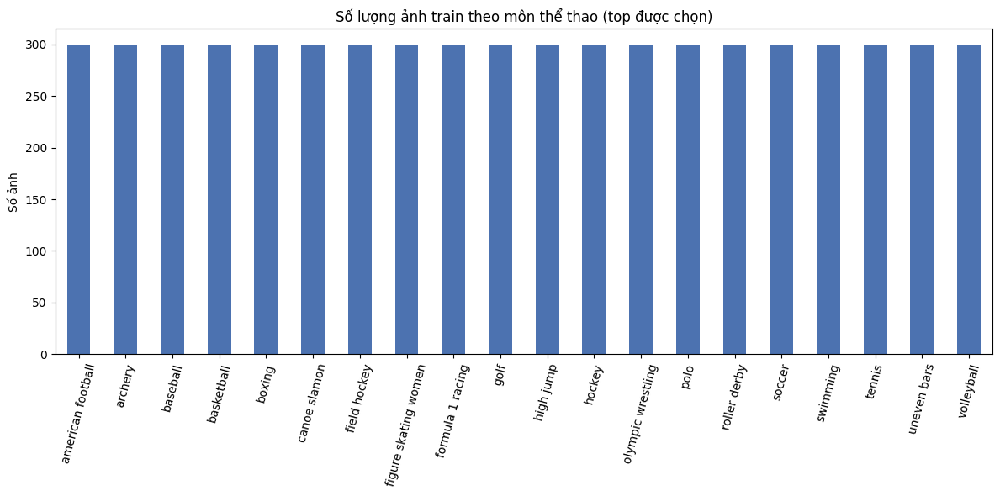

In [8]:
plt.figure(figsize=(12, 6))
train_counts.loc[SELECTED_CLASSES].plot(kind="bar", color="#4C72B0")
plt.title("Số lượng ảnh train theo môn thể thao (top được chọn)")
plt.ylabel("Số ảnh")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


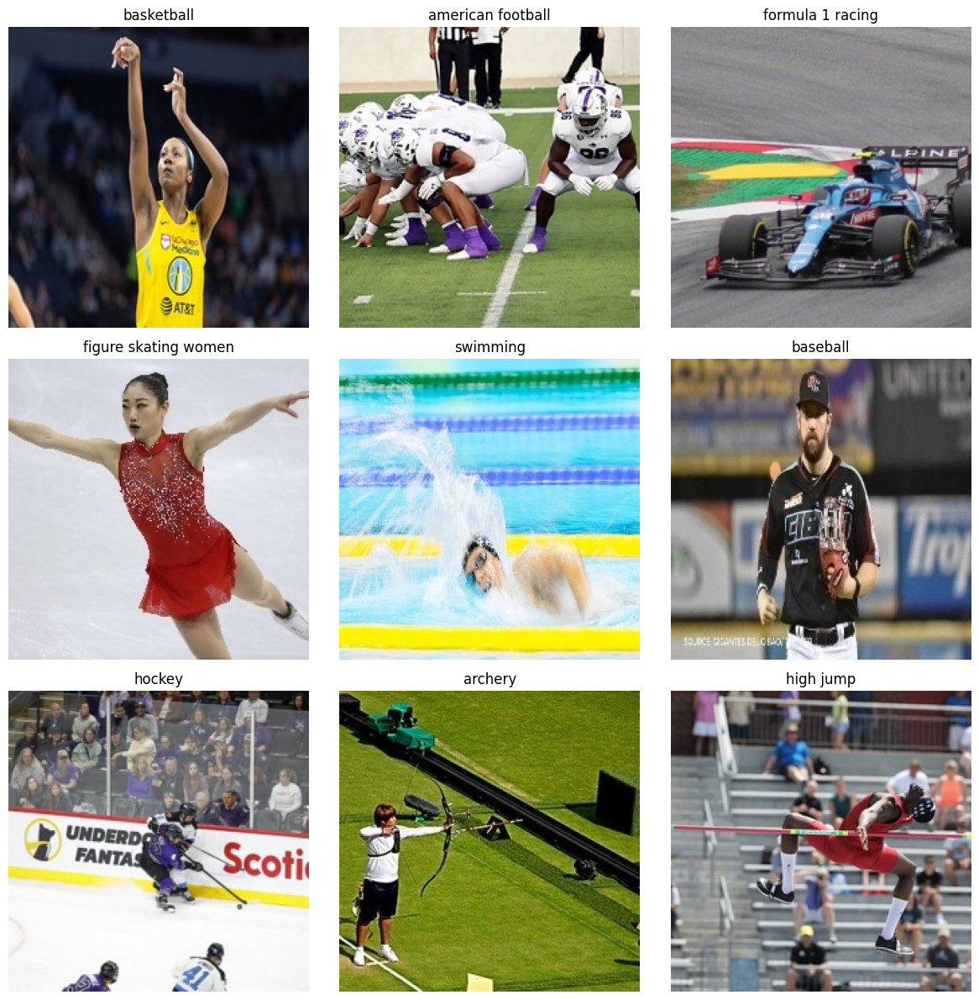

In [9]:
def show_sample_images(directory, classes, n_per_class=1, seed=SEED):
    rng = random.Random(seed)
    chosen = rng.sample(classes, min(9, len(classes)))
    plt.figure(figsize=(12, 12))
    for i, c in enumerate(chosen):
        files = [f for f in glob.glob(os.path.join(directory, c, "*")) if f.lower().endswith(VALID_IMAGE_EXTS)]
        if not files:
            continue
        f = rng.choice(files)
        img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(c)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, SELECTED_CLASSES)


## 4. Xây dựng pipeline dữ liệu (tiền xử lý + Data Augmentation)

Dùng `image_dataset_from_directory` để tạo `tf.data.Dataset`, chỉ giữ lại các lớp trong `SELECTED_CLASSES`.
Augmentation (lật ngang, xoay nhẹ, zoom, chỉnh sáng) được áp dụng **chỉ trên tập train** để giảm overfitting.


In [10]:
def make_filtered_dataset(directory, classes, img_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        class_names=sorted(classes),
        image_size=img_size,
        batch_size=batch_size,
        shuffle=shuffle,
        seed=SEED,
    )
    return ds

train_ds_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
valid_ds_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
test_ds_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Số lớp:", NUM_CLASSES)
print(CLASS_NAMES)


Found 6000 files belonging to 20 classes.
Found 300 files belonging to 20 classes.
Found 500 files belonging to 20 classes.
Số lớp: 20
['american football', 'archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'soccer', 'swimming', 'tennis', 'uneven bars', 'volleyball']


In [11]:
# ==== NÂNG CẤP V3: BỘ TĂNG CƯỜNG DỮ LIỆU ĐẶC TRỊ CAMERA (CAMERA-RESILIENT) ====
# Chống lóa sáng màn hình điện thoại, chịu nghiêng góc, thu phóng và thích ứng ánh sáng thực tế
data_augmentation = keras.Sequential([
    # 1. Biến đổi hình học & góc nhìn (Geometric)
    layers.RandomFlip("horizontal"),                       # Lật ngang (trái/phải)
    layers.RandomRotation(0.10),                           # Xoay nghiêng góc ±10% (~36 độ, thực tế hơn ±54 độ)
    layers.RandomZoom(height_factor=(-0.2, 0.2)),          # Thu phóng xa/gần (chụp toàn cảnh hoặc cận cảnh)
    layers.RandomTranslation(0.10, 0.10),                  # Dịch chuyển vị trí chủ thể lệch tâm

    # 2. Xử lý quang học & cảm biến camera (Photometric & Sensor)
    layers.RandomContrast(0.30),                           # Chống lóa sáng màn hình và đèn flash
    layers.RandomBrightness(0.30, value_range=(0, 255)),   # Thích nghi phòng tối, ngoài trời nắng
    layers.Rescaling(1.0 / 255.0),
    layers.GaussianNoise(0.02),                            # Giả lập nhiễu hạt sensor ~2% (Keras 3 yêu cầu 0 <= stddev <= 1)
    layers.Rescaling(255.0),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE
SHUFFLE_BUFFER = 1000

def prep_dataset(ds, augment=False, preprocess_fn=None, cache=True, onehot=False):
    """onehot=True: đổi nhãn int -> one-hot (cần cho CategoricalCrossentropy có label smoothing).
    Chỉ dùng onehot cho tập train/valid khi fit; tập test giữ nhãn int để dùng với sklearn."""
    if cache:
        ds = ds.cache()
    if augment:
        ds = ds.unbatch().shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    if preprocess_fn is not None:
        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    if onehot:
        ds = ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


### 4.1. Trực quan hóa dữ liệu sau khi Tăng cường (Visualizing Augmentation Grid 3×3)
Mỗi lần chạy sẽ áp dụng ngẫu nhiên các phép lật, xoay nghiêng, co giãn, chỉnh tương phản/độ sáng và nhiễu hạt lên ảnh gốc.

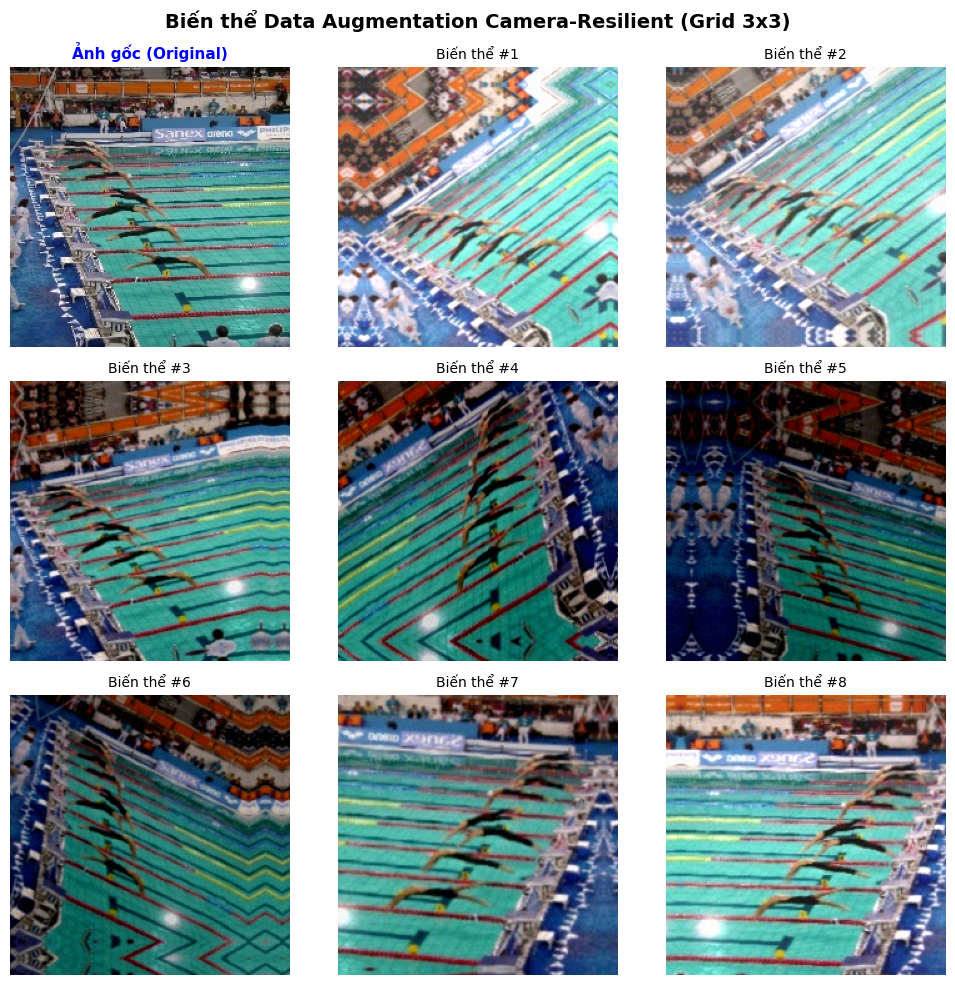

In [12]:
# ==== TRỰC QUAN HÓA DATA AUGMENTATION (GRID 3x3) ====
# Lấy 1 bức ảnh mẫu từ tập train và hiển thị 9 biến thể ngẫu nhiên mà mô hình sẽ học
def visualize_augmentation(dataset_raw, augment_layer, title="Biến thể Data Augmentation Camera-Resilient (Grid 3x3)"):
    for images, _ in dataset_raw.take(1):
        sample_img = images[0]
        break

    plt.figure(figsize=(10, 10))
    # Hiển thị ảnh gốc ở ô đầu tiên
    plt.subplot(3, 3, 1)
    plt.imshow(sample_img.numpy().astype("uint8"))
    plt.title("Ảnh gốc (Original)", fontsize=11, fontweight="bold", color="blue")
    plt.axis("off")

    # 8 ô còn lại hiển thị các biến thể sau augmentation
    for i in range(1, 9):
        augmented_img = augment_layer(tf.expand_dims(sample_img, 0), training=True)
        clipped_img = tf.clip_by_value(augmented_img[0], 0, 255).numpy().astype("uint8")
        plt.subplot(3, 3, i + 1)
        plt.imshow(clipped_img)
        plt.title(f"Biến thể #{i}", fontsize=10)
        plt.axis("off")

    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Hiển thị trực quan ngay lập tức
visualize_augmentation(train_ds_raw, data_augmentation)


## 5. Xây dựng các mô hình

Ba mô hình sẽ được huấn luyện và so sánh:
1. **CNN từ đầu** (baseline, không dùng pretrained weights)
2. **MobileNetV2** (transfer learning, fine-tune)
3. **ResNet50** (transfer learning, fine-tune) — đại diện họ ResNet (thay cho ResNet18)


In [13]:
def conv_bn(x, filters, name=None):
    x = layers.Conv2D(filters, 3, activation="relu", padding="same", name=name)(x)
    return layers.BatchNormalization()(x)   # BN đặt SAU ReLU -> lớp Conv "last_conv" vẫn là mục tiêu Grad-CAM hợp lệ

def build_cnn_scratch(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = conv_bn(x, 32);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 64);  x = conv_bn(x, 64);   x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 128); x = conv_bn(x, 128);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 256, name="last_conv");     x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Scratch")


def build_transfer_model(base_class, input_shape, num_classes, name):
    base = base_class(include_top=False, weights="imagenet", input_shape=input_shape)
    base.trainable = False  # đóng băng ban đầu, sẽ fine-tune sau
    inputs = keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, base


INPUT_SHAPE = IMG_SIZE + (3,)

cnn_scratch = build_cnn_scratch(INPUT_SHAPE, NUM_CLASSES)
cnn_scratch.summary()


Model: "CNN_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 646,548 (2.47 MB)

 Trainable params: 645,204 (2.46 MB)

 Non-trainable params: 1,344 (5.25 KB)

## 6. Huấn luyện & so sánh 3 mô hình

In [14]:
EPOCHS_HEAD = 10       # huấn luyện đầu (frozen base với 2 mô hình transfer)
EPOCHS_FINETUNE = 25   # fine-tune thêm (EarlyStopping sẽ dừng đúng lúc)
FINETUNE_LR = 3e-5     # đỉnh của cosine decay khi fine-tune
# MobileNetV2 có 154 lớp (mở 80 lớp cuối); ResNet50 có 175 lớp (mở 55 lớp cuối = conv4 cuối + toàn bộ conv5)
UNFREEZE = {"MobileNetV2": 80, "ResNet50": 55}

def make_loss():
    return keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

def cosine_schedule(peak_lr, total_epochs, min_lr=1e-7, warmup_epochs=1):
    def fn(epoch):
        if epoch < warmup_epochs:
            return float(peak_lr * (epoch + 1) / (warmup_epochs + 1))
        t = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return float(min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * min(1.0, t))))
    return fn

class SaveBestEpochCallback(keras.callbacks.Callback):
    """Lưu lại số epoch tốt nhất (theo val_loss) cạnh tệp checkpoint .keras."""
    def __init__(self, meta_path):
        super().__init__()
        self.meta_path = str(meta_path)
        self.best = float("inf")

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        if val_loss is not None and float(val_loss) < self.best:
            self.best = float(val_loss)
            meta = {
                "best_epoch": int(epoch + 1),
                "val_loss": float(val_loss),
                "val_accuracy": float(logs.get("val_accuracy")) if logs.get("val_accuracy") is not None else None,
            }
            with open(self.meta_path, "w", encoding="utf-8") as f:
                json.dump(meta, f, ensure_ascii=False, indent=2)

def warn_if_label_mismatch(model_path):
    if "CLASS_NAMES" not in globals():
        return
    model_dir = os.path.dirname(os.path.abspath(model_path))
    for lbl_cand in [
        os.path.join(model_dir, "labels.json"),
        os.path.join(model_dir, "class_names.json"),
        os.path.join(model_dir, "sportsnap_model", "class_names.json"),
    ]:
        if os.path.exists(lbl_cand):
            with open(lbl_cand, "r", encoding="utf-8") as f:
                ckpt_labels = json.load(f)
            if list(ckpt_labels) != list(CLASS_NAMES):
                diff_ckpt = sorted(set(ckpt_labels) - set(CLASS_NAMES))
                diff_curr = sorted(set(CLASS_NAMES) - set(ckpt_labels))
                print(
                    f"[Cảnh báo] Checkpoint '{model_path}' dùng bộ nhãn khác với CLASS_NAMES hiện tại! "
                    f"(Thừa trong checkpoint: {diff_ckpt}; mới trong dataset: {diff_curr})."
                )
            return

def format_checkpoint_epoch(model_path):
    """Đọc số epoch tốt nhất từ tệp .epoch.json cạnh checkpoint (hoặc ngày lưu trong .keras)."""
    mp = pathlib.Path(model_path)
    meta_file = mp.with_suffix(".epoch.json")
    if meta_file.is_file():
        meta = json.loads(meta_file.read_text(encoding="utf-8"))
        ep = meta.get("best_epoch")
        vl = meta.get("val_loss")
        va = meta.get("val_accuracy")
        parts = [f"epoch {ep}"]
        if vl is not None:
            parts.append(f"val_loss={vl:.4f}")
        if va is not None:
            parts.append(f"val_acc={va:.4f}")
        return ", ".join(parts)
    try:
        with zipfile.ZipFile(mp, "r") as z:
            if "metadata.json" in z.namelist():
                m = json.loads(z.read("metadata.json").decode("utf-8"))
                if "date_saved" in m:
                    return f"chưa có .epoch.json (lưu lúc {m['date_saved']})"
    except Exception:
        pass
    return "chưa rõ epoch"

def load_model_with_epoch(model_path, var_name=None, compile=False):
    label = var_name or pathlib.Path(model_path).name
    epoch_info = format_checkpoint_epoch(model_path)
    print(f"[SportSnap] Nạp {label} từ checkpoint: {model_path} ({epoch_info})")
    warn_if_label_mismatch(model_path)
    return tf.keras.models.load_model(model_path, compile=compile)

def safe_clear_session(reset_globals=True):
    """Dọn sạch phiên TensorFlow, bộ nhớ RAM/VRAM, cache Grad-CAM và các tham chiếu model đã hết hiệu lực."""
    if "_GRADCAM_GRAPH_CACHE" in globals():
        globals().get('_GRADCAM_GRAPH_CACHE', {}).clear()
    if reset_globals:
        for _k in ("cnn_scratch", "mobilenet_model", "resnet_model", "best_model"):
            if _k in globals():
                globals()[_k] = None
    keras.backend.clear_session()
    gc.collect()

def _find_checkpoint_any(filename):
    search = [".", "/kaggle/working", r"d:\tgmt\all_sportsnap_outputs", r"../all_sportsnap_outputs"]
    if globals().get("MODEL_DIR"):
        search.insert(0, MODEL_DIR)
    for d in dict.fromkeys(search):
        if not d:
            continue
        p = os.path.join(d, filename)
        if os.path.exists(p):
            return p
    return None

def ensure_main_models_loaded(names=("cnn_scratch", "mobilenet_model", "resnet_model")):
    """Đảm bảo 3 mô hình chính luôn sẵn sàng trong RAM (tự nạp lại từ *_best.keras sau safe_clear_session)."""
    spec_map = {
        "cnn_scratch": "cnn_scratch_best.keras",
        "mobilenet_model": "MobileNetV2_finetune_best.keras",
        "resnet_model": "ResNet50_finetune_best.keras",
    }
    for var_name in names:
        if globals().get(var_name) is not None:
            continue
        ckpt = spec_map[var_name]
        p = _find_checkpoint_any(ckpt)
        if p is not None:
            globals()[var_name] = load_model_with_epoch(p, var_name=var_name, compile=False)
        else:
            raise FileNotFoundError(f"Chưa có {var_name} trong bộ nhớ và không tìm thấy {ckpt}.")

def get_callbacks(name, checkpoint=True, plateau=True, lr_fn=None, patience=8):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if checkpoint:
        cbs.append(keras.callbacks.ModelCheckpoint(f"{name}_best.keras", monitor="val_loss", save_best_only=True))
        cbs.append(SaveBestEpochCallback(f"{name}_best.epoch.json"))
    if plateau:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2))
    if lr_fn is not None:
        cbs.append(keras.callbacks.LearningRateScheduler(lr_fn))
    return cbs

def freeze_batchnorm(base_model):
    """Đóng băng BatchNorm khi fine-tune để không phá thống kê ImageNet trên tập nhỏ."""
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def unfreeze_top_layers(base_model, n_layers):
    """Progressive unfreezing: chỉ mở khóa n_layers cuối của base, BN vẫn đóng băng."""
    base_model.trainable = True
    for layer in base_model.layers[:-n_layers]:
        layer.trainable = False
    freeze_batchnorm(base_model)

def quick_acc(model, ds):
    """Accuracy trên ds có nhãn int (test), không phụ thuộc loss của model."""
    y = np.concatenate([b.numpy() for _, b in ds])
    return accuracy_score(y, np.argmax(model.predict(ds, verbose=0), axis=1))

def train_transfer_model(base_class, preprocess_fn, name, train_raw, valid_raw,
                         unfreeze_n, head_eval_ds=None, checkpoint=True,
                         epochs_head=None, epochs_ft=None, cache_train=True, verbose=1):
    """Huấn luyện 2 giai đoạn: (1) head với base đóng băng, (2) fine-tune top layers + cosine LR.
    Trả về (model, base, history_gộp, info). info['head_test_acc'] = accuracy khi CHỈ train head (Frozen)."""
    epochs_head = EPOCHS_HEAD if epochs_head is None else epochs_head
    epochs_ft = EPOCHS_FINETUNE if epochs_ft is None else epochs_ft
    model, base = build_transfer_model(base_class, INPUT_SHAPE, NUM_CLASSES, f"{name}_Transfer")
    tr = prep_dataset(train_raw, augment=True,  preprocess_fn=preprocess_fn, cache=cache_train, onehot=True)
    va = prep_dataset(valid_raw, augment=False, preprocess_fn=preprocess_fn, cache=cache_train, onehot=True)

    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
    h1 = model.fit(tr, validation_data=va, epochs=epochs_head, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_head", checkpoint=checkpoint))
    info = {}
    if head_eval_ds is not None:
        info["head_test_acc"] = quick_acc(model, head_eval_ds)

    unfreeze_top_layers(base, unfreeze_n)
    model.compile(optimizer=keras.optimizers.Adam(FINETUNE_LR), loss=make_loss(), metrics=["accuracy"])
    h2 = model.fit(tr, validation_data=va, epochs=epochs_ft, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_finetune", checkpoint=checkpoint, plateau=False,
                                           lr_fn=cosine_schedule(FINETUNE_LR, epochs_ft), patience=10))
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history if k in h2.history}
    return model, base, hist, info

histories = {}
head_only_acc = {}   # accuracy test khi chỉ train head (Frozen) -> so sánh Frozen vs Fine-tuning


In [15]:
# ---- 1) CNN từ đầu ----
train_ds = prep_dataset(train_ds_raw, augment=True, onehot=True)
valid_ds = prep_dataset(valid_ds_raw, augment=False, onehot=True)
test_ds  = prep_dataset(test_ds_raw, augment=False)          # nhãn int

cnn_scratch.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])

EPOCHS_SCRATCH = 50
hist_cnn = cnn_scratch.fit(
    train_ds, validation_data=valid_ds, epochs=EPOCHS_SCRATCH,
    callbacks=get_callbacks("cnn_scratch", plateau=False,
                            lr_fn=cosine_schedule(1e-3, EPOCHS_SCRATCH, min_lr=1e-6, warmup_epochs=2),
                            patience=12))
histories["CNN_Scratch"] = hist_cnn.history


Epoch 1/50


E0000 00:00:1795248955.604725      79 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795248962.539339      79 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    187/Unknown 98s 365ms/step - accuracy: 0.2247 - loss: 2.6745

E0000 00:00:1795249040.802121      79 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795249041.592989      79 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    188/Unknown 111s 432ms/step - accuracy: 0.2251 - loss: 2.6732

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 116s 457ms/step - accuracy: 0.3000 - loss: 2.4439 - val_accuracy: 0.0900 - val_loss: 3.4785 - learning_rate: 3.3333e-04
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - accuracy: 0.4038 - loss: 2.1572 - val_accuracy: 0.1300 - val_loss: 3.5190 - learning_rate: 6.6667e-04
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 229ms/step - accuracy: 0.4618 - loss: 2.0039 - val_accuracy: 0.4367 - val_loss: 2.2291 - learning_rate: 0.0010
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - accuracy: 0.5282 - loss: 1.8482 - val_accuracy: 0.5467 - val_loss: 1.8812 - learning_rate: 9.9893e-04
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 226ms/step - accuracy: 0.5698 - loss: 1.7504 - val_accuracy: 0.5133 - val_loss: 1.8786 - learning_rate: 9.9573e-04
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - accuracy: 0.6130 - loss: 1.6502 - val_accuracy: 0.4200 - val_loss: 2.2315 - learning_rate: 9.9040e-04
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 225ms/step - acc

In [16]:
# ---- 2) MobileNetV2 (transfer learning) ----
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)

mobilenet_model, mobilenet_base, hist_mnv2, info_mnv2 = train_transfer_model(
    MobileNetV2, mnv2_preprocess, "MobileNetV2", train_ds_raw, valid_ds_raw,
    unfreeze_n=UNFREEZE["MobileNetV2"], head_eval_ds=test_ds_mnv2)
histories["MobileNetV2"] = hist_mnv2
head_only_acc["MobileNetV2"] = info_mnv2["head_test_acc"]


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 279ms/step - accuracy: 0.5638 - loss: 1.7937 - val_accuracy: 0.9000 - val_loss: 1.0361 - learning_rate: 0.0010
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 223ms/step - accuracy: 0.7830 - loss: 1.2381 - val_accuracy: 0.9233 - val_loss: 0.9457 - learning_rate: 0.0010
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 223ms/step - accuracy: 0.8210 - loss: 1.1654 - val_accuracy: 0.9300 - val_loss: 0.9309 - learning_rate: 0.0010
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.8393 - loss: 1.1241 - val_accuracy: 0.9367 - val_loss: 0.9157 - learning_rate: 0.0010
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 222ms/step - accuracy: 0.8523 - loss: 1.0856 - val_accuracy: 0.9400 - val_loss: 0.8885 - learning_rate: 0.0010
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 82s 221ms/step - accuracy: 0.8590 - loss: 1.0788 - val_accuracy: 0.9500 - val_loss: 0.8843 - learning_rate: 0.0010
Epoch 7/10
188/188 ━━

E0000 00:00:1795251847.176876      78 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    188/Unknown 65s 251ms/step - accuracy: 0.8881 - loss: 1.0154

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 287ms/step - accuracy: 0.8895 - loss: 0.9998 - val_accuracy: 0.9200 - val_loss: 0.8878 - learning_rate: 1.5000e-05
Epoch 2/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 222ms/step - accuracy: 0.8992 - loss: 0.9723 - val_accuracy: 0.9400 - val_loss: 0.8689 - learning_rate: 3.0000e-05
Epoch 3/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 223ms/step - accuracy: 0.9220 - loss: 0.9111 - val_accuracy: 0.9333 - val_loss: 0.8755 - learning_rate: 2.9872e-05
Epoch 4/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 226ms/step - accuracy: 0.9288 - loss: 0.8833 - val_accuracy: 0.9467 - val_loss: 0.8463 - learning_rate: 2.9491e-05
Epoch 5/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 225ms/step - accuracy: 0.9420 - loss: 0.8554 - val_accuracy: 0.9400 - val_loss: 0.8205 - learning_rate: 2.8862e-05
Epoch 6/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 224ms/step - accuracy: 0.9493 - loss: 0.8376 - val_accuracy: 0.9500 - val_loss: 0.8084 - learning_rate: 2.7997e-05
Epoch 7/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 217ms/step - 

In [17]:
# ---- 3) ResNet50 (transfer learning) ----
test_ds_res  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds_res = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

resnet_model, resnet_base, hist_res, info_res = train_transfer_model(
    ResNet50, resnet_preprocess, "ResNet50", train_ds_raw, valid_ds_raw,
    unfreeze_n=UNFREEZE["ResNet50"], head_eval_ds=test_ds_res)
histories["ResNet50"] = hist_res
head_only_acc["ResNet50"] = info_res["head_test_acc"]


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 77s 310ms/step - accuracy: 0.6400 - loss: 1.6621 - val_accuracy: 0.9100 - val_loss: 1.0235 - learning_rate: 0.0010
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 248ms/step - accuracy: 0.8292 - loss: 1.1724 - val_accuracy: 0.8867 - val_loss: 1.0222 - learning_rate: 0.0010
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 248ms/step - accuracy: 0.8658 - loss: 1.0865 - val_accuracy: 0.9367 - val_loss: 0.9724 - learning_rate: 0.0010
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 251ms/step - accuracy: 0.8795 - loss: 1.0468 - val_accuracy: 0.9367 - val_loss: 0.9451 - learning_rate: 0.0010
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 80s 241ms/step - accuracy: 0.8960 - loss: 1.0096 - val_accuracy: 0.9333 - val_loss: 0.9623 - learning_rate: 0.0010
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 84s 250ms/step - accuracy: 0.9037 - loss: 0.9851 - val_accuracy: 0.9500 - val_loss: 0.9320 - learning_rate: 0.0010
Epoch 7/10
188/188 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 329ms/step - accuracy: 0.9422 - loss: 0.8802 - val_accuracy: 0.9600 - val_loss: 0.8371 - learning_rate: 1.5000e-05
Epoch 2/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 57s 257ms/step - accuracy: 0.9563 - loss: 0.8413 - val_accuracy: 0.9667 - val_loss: 0.8157 - learning_rate: 3.0000e-05
Epoch 3/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 259ms/step - accuracy: 0.9647 - loss: 0.8105 - val_accuracy: 0.9633 - val_loss: 0.8073 - learning_rate: 2.9872e-05
Epoch 4/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 258ms/step - accuracy: 0.9723 - loss: 0.7830 - val_accuracy: 0.9600 - val_loss: 0.8006 - learning_rate: 2.9491e-05
Epoch 5/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 257ms/step - accuracy: 0.9810 - loss: 0.7553 - val_accuracy: 0.9700 - val_loss: 0.7849 - learning_rate: 2.8862e-05
Epoch 6/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 82s 257ms/step - accuracy: 0.9857 - loss: 0.7385 - val_accuracy: 0.9800 - val_loss: 0.7659 - learning_rate: 2.7997e-05
Epoch 7/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 49s 251ms/step - 

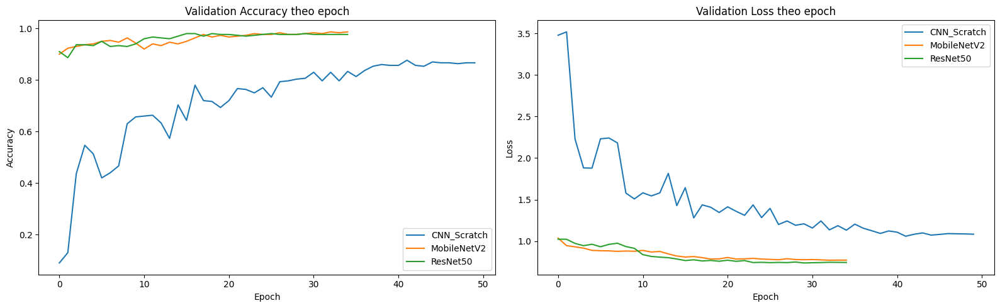

In [18]:
# Biểu đồ so sánh accuracy / loss giữa 3 mô hình
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=name)
    axes[1].plot(h["val_loss"], label=name)
axes[0].set_title("Validation Accuracy theo epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].set_title("Validation Loss theo epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Đánh giá trên tập test: Accuracy, Classification Report, Confusion Matrix

In [19]:
# Tự động dùng model đã train trong bộ nhớ; chỉ nạp từ checkpoint nếu chạy nhảy cóc tới Mục 7
test_ds       = prep_dataset(test_ds_raw, augment=False)
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
test_ds_res   = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds      = prep_dataset(valid_ds_raw, augment=False, onehot=True)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)
valid_ds_res  = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

if "histories" not in globals():
    histories = {}
if "head_only_acc" not in globals():
    head_only_acc = {}

ensure_main_models_loaded()

for name, ds in [("MobileNetV2", test_ds_mnv2), ("ResNet50", test_ds_res)]:
    if name not in head_only_acc:
        p_head = _find_checkpoint_any(f"{name}_head_best.keras")
        if p_head is not None:
            m_head = load_model_with_epoch(p_head, var_name=f"{name}_head", compile=False)
            head_only_acc[name] = quick_acc(m_head, ds)
            del m_head
print("Head-only (Frozen) Test Accuracy:", head_only_acc)


Head-only (Frozen) Test Accuracy: {'MobileNetV2': 0.916, 'ResNet50': 0.942}


===== CNN_Scratch — Test Accuracy: 0.8340 =====
                      precision    recall  f1-score   support

   american football       0.72      0.92      0.81        25
             archery       0.70      0.84      0.76        25
            baseball       0.96      0.92      0.94        25
          basketball       0.62      0.92      0.74        25
              boxing       0.83      0.76      0.79        25
        canoe slamon       1.00      1.00      1.00        25
        field hockey       0.70      0.64      0.67        25
figure skating women       0.96      1.00      0.98        25
    formula 1 racing       0.93      1.00      0.96        25
                golf       0.81      0.84      0.82        25
           high jump       0.89      0.68      0.77        25
              hockey       0.96      0.96      0.96        25
   olympic wrestling       0.86      0.96      0.91        25
                polo       1.00      0.84      0.91        25
        roller derby 

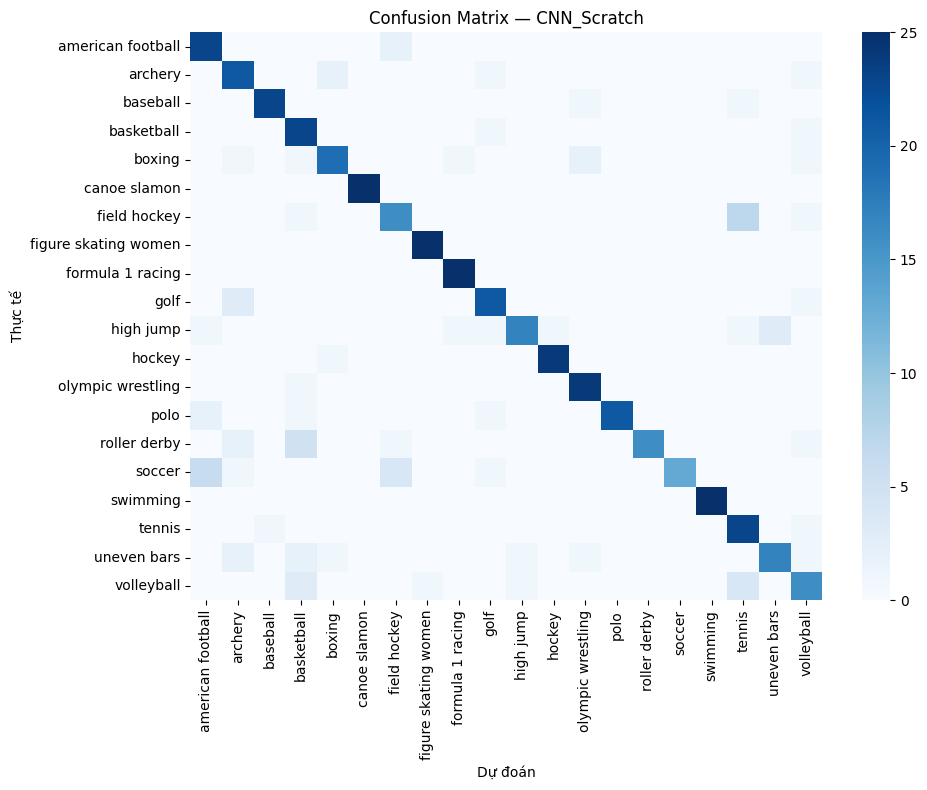

===== MobileNetV2 — Test Accuracy: 0.9660 =====
                      precision    recall  f1-score   support

   american football       0.96      1.00      0.98        25
             archery       0.89      1.00      0.94        25
            baseball       0.96      1.00      0.98        25
          basketball       0.96      1.00      0.98        25
              boxing       1.00      0.96      0.98        25
        canoe slamon       1.00      1.00      1.00        25
        field hockey       1.00      0.88      0.94        25
figure skating women       1.00      0.96      0.98        25
    formula 1 racing       1.00      1.00      1.00        25
                golf       0.96      0.92      0.94        25
           high jump       1.00      0.92      0.96        25
              hockey       1.00      1.00      1.00        25
   olympic wrestling       0.89      0.96      0.92        25
                polo       1.00      1.00      1.00        25
        roller derby 

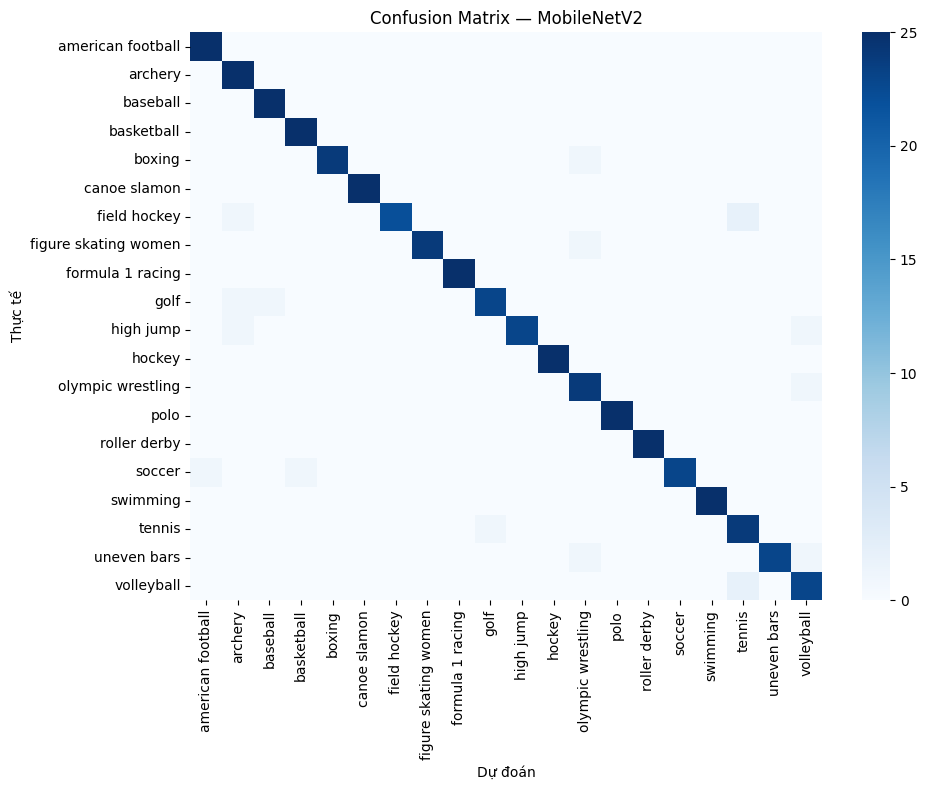

===== ResNet50 — Test Accuracy: 0.9780 =====
                      precision    recall  f1-score   support

   american football       0.92      0.96      0.94        25
             archery       0.96      1.00      0.98        25
            baseball       0.96      1.00      0.98        25
          basketball       1.00      1.00      1.00        25
              boxing       0.96      0.92      0.94        25
        canoe slamon       1.00      1.00      1.00        25
        field hockey       1.00      0.92      0.96        25
figure skating women       1.00      1.00      1.00        25
    formula 1 racing       1.00      1.00      1.00        25
                golf       1.00      1.00      1.00        25
           high jump       1.00      1.00      1.00        25
              hockey       1.00      1.00      1.00        25
   olympic wrestling       0.93      1.00      0.96        25
                polo       1.00      1.00      1.00        25
        roller derby    

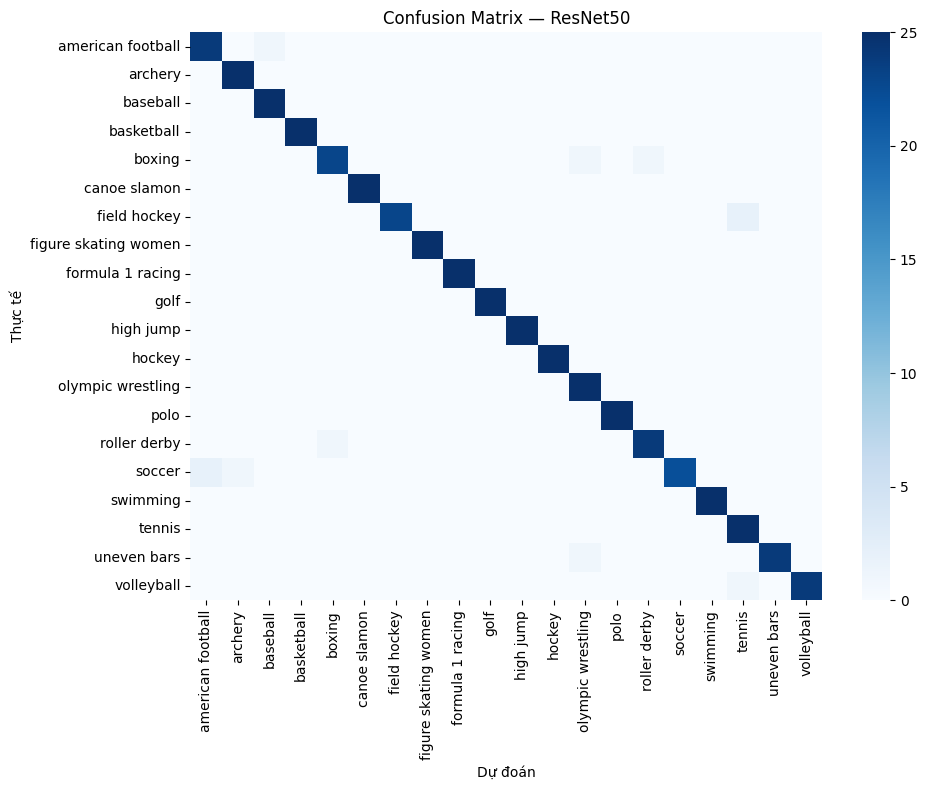

In [20]:
eval_store = {}   # lưu (y_true, xác suất dự đoán) để dùng lại cho phân tích lỗi / ensemble, không phải predict lại

def evaluate_model(model, ds, class_names, name):
    # ds test KHÔNG shuffle nên thứ tự nhãn và thứ tự dự đoán luôn khớp nhau.
    # Predict cả dataset 1 lần (nhanh hơn và không bị cảnh báo tf.function retracing như predict từng batch).
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    eval_store[name] = (y_true, probs)

    acc = accuracy_score(y_true, y_pred)
    print(f"===== {name} — Test Accuracy: {acc:.4f} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
    plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return acc

results = {}
results["CNN_Scratch"] = evaluate_model(cnn_scratch, test_ds, CLASS_NAMES, "CNN_Scratch")
results["MobileNetV2"] = evaluate_model(mobilenet_model, test_ds_mnv2, CLASS_NAMES, "MobileNetV2")
results["ResNet50"] = evaluate_model(resnet_model, test_ds_res, CLASS_NAMES, "ResNet50")


In [21]:
summary_df = pd.DataFrame({
    "Mô hình": list(results.keys()),
    "Test Accuracy": [round(v, 4) for v in results.values()],
}).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

summary_df["Đạt mục tiêu (>=0.88)"] = summary_df["Test Accuracy"] >= 0.88
print(summary_df.to_string(index=False))

# So sánh Frozen (chỉ train head) vs Fine-tuning – theo bản phân công của nhóm
ft_df = pd.DataFrame({
    "Mô hình": list(head_only_acc.keys()),
    "Test Acc (Frozen)": [round(v, 4) for v in head_only_acc.values()],
    "Test Acc (Fine-tune)": [round(results[k], 4) for k in head_only_acc],
})
ft_df["Chênh lệch"] = (ft_df["Test Acc (Fine-tune)"] - ft_df["Test Acc (Frozen)"]).round(4)
print(ft_df.to_string(index=False))

EXPERIMENT_SUMMARY["test_accuracy"] = {k: round(float(v), 4) for k, v in results.items()}
EXPERIMENT_SUMMARY["head_only_frozen_test_accuracy"] = {k: round(float(v), 4) for k, v in head_only_acc.items()}


    Mô hình  Test Accuracy  Đạt mục tiêu (>=0.88)
   ResNet50          0.978                   True
MobileNetV2          0.966                   True
CNN_Scratch          0.834                  False
    Mô hình  Test Acc (Frozen)  Test Acc (Fine-tune)  Chênh lệch
MobileNetV2              0.916                 0.966       0.050
   ResNet50              0.942                 0.978       0.036


### 7b. Phân tích lỗi (các cặp lớp bị nhầm) & thử Ensemble

Phân tích các cặp môn thể thao hay bị nhầm lẫn nhất trên tập test, đồng thời thử nghiệm Test-Time Augmentation (lật ngang) và Ensemble (MobileNetV2 + ResNet50).


In [22]:
def top_confusions(name, class_names, k=8):
    y_true, probs = eval_store[name]
    y_pred = probs.argmax(1)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    np.fill_diagonal(cm, 0)
    pairs = sorted([(cm[i, j], class_names[i], class_names[j])
                    for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0], reverse=True)
    print(f"--- {name}: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---")
    for n, t, p in pairs[:k]:
        print(f"  {t} -> {p}: {n} ảnh")
    print()

for n in ["CNN_Scratch", "MobileNetV2", "ResNet50"]:
    top_confusions(n, CLASS_NAMES)

# Ensemble: trung bình xác suất MobileNetV2 + ResNet50 (chỉ để thử nghiệm/báo cáo; không lưu thành 1 file model)
y_m, p_m = eval_store["MobileNetV2"]
y_r, p_r = eval_store["ResNet50"]
assert (y_m == y_r).all(), "Thứ tự test của 2 mô hình không khớp"
ens_acc = accuracy_score(y_m, (p_m + p_r).argmax(1))
print(f"Ensemble MobileNetV2 + ResNet50 — Test Accuracy: {ens_acc:.4f}")
print(f"(Test có {len(y_m)} ảnh: 1 ảnh sai = {100 / len(y_m):.2f}% accuracy)")

# ---- TTA (lật ngang) + ensemble có trọng số ----
def predict_probs_tta(model, ds):
    flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
    return (model.predict(ds, verbose=0) + model.predict(flipped, verbose=0)) / 2

p_m_tta = predict_probs_tta(mobilenet_model, test_ds_mnv2)
p_r_tta = predict_probs_tta(resnet_model, test_ds_res)
print(f"MobileNetV2 + TTA         : {accuracy_score(y_m, p_m_tta.argmax(1)):.4f}")
print(f"ResNet50    + TTA         : {accuracy_score(y_m, p_r_tta.argmax(1)):.4f}")
print(f"Ensemble (0.3/0.7) + TTA  : {accuracy_score(y_m, (0.3 * p_m_tta + 0.7 * p_r_tta).argmax(1)):.4f}")
print(f"Lưu ý: tập test gồm {len(y_m)} ảnh (1 ảnh ≈ {100/len(y_m):.2f}% accuracy) -> đối chiếu thêm K-Fold (mục 7c) và Multi-seed (mục 12.1).")

EXPERIMENT_SUMMARY["ensemble_and_tta"] = {
    "ensemble_avg": round(float(ens_acc), 4),
    "mobilenetv2_tta": round(float(accuracy_score(y_m, p_m_tta.argmax(1))), 4),
    "resnet50_tta": round(float(accuracy_score(y_m, p_r_tta.argmax(1))), 4),
    "ensemble_03_07_tta": round(float(accuracy_score(y_m, (0.3 * p_m_tta + 0.7 * p_r_tta).argmax(1))), 4),
    "test_count": int(len(y_m)),
}


--- CNN_Scratch: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---
  field hockey -> tennis: 7 ảnh
  soccer -> american football: 6 ảnh
  roller derby -> basketball: 5 ảnh
  volleyball -> tennis: 4 ảnh
  soccer -> field hockey: 4 ảnh
  volleyball -> basketball: 3 ảnh
  high jump -> uneven bars: 3 ảnh
  golf -> archery: 3 ảnh

--- MobileNetV2: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---
  volleyball -> tennis: 2 ảnh
  field hockey -> tennis: 2 ảnh
  uneven bars -> volleyball: 1 ảnh
  uneven bars -> olympic wrestling: 1 ảnh
  tennis -> golf: 1 ảnh
  soccer -> basketball: 1 ảnh
  soccer -> american football: 1 ảnh
  olympic wrestling -> volleyball: 1 ảnh

--- ResNet50: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---
  soccer -> american football: 2 ảnh
  field hockey -> tennis: 2 ảnh
  volleyball -> tennis: 1 ảnh
  uneven bars -> olympic wrestling: 1 ảnh
  soccer -> archery: 1 ảnh
  roller derby -> boxing: 1 ảnh
  boxing -> roller derby: 1 ảnh
  boxing -> olympic wrestling: 

### 7c. Stratified K-Fold Cross-Validation (đánh giá đáng tin hơn)

Gộp toàn bộ **train + valid + test** của 20 lớp, chia `KFOLD` fold phân tầng theo lớp; mỗi fold huấn luyện trên phần còn lại (trong đó 10% làm validation nội bộ để early stopping — **fold giữ lại không bao giờ dùng để chọn epoch**), rồi dự đoán fold đó và gộp dự đoán ngoài-fold (OOF) cho toàn bộ ảnh.

Bật bằng `RUN_KFOLD = True` ở mục 2.


In [23]:
def collect_all_paths():
    paths, labels = [], []
    for d in dict.fromkeys([TRAIN_DIR, VALID_DIR, TEST_DIR]):
        for ci, cname in enumerate(CLASS_NAMES):
            for f in sorted(glob.glob(os.path.join(d, cname, "*"))):
                if f.lower().endswith(VALID_IMAGE_EXTS):
                    paths.append(f); labels.append(ci)
    return np.array(paths), np.array(labels)

def _load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape(IMG_SIZE + (3,))
    return img, label

def paths_to_ds(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    return ds.map(_load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)

def run_kfold(model_name=KFOLD_MODEL, k=KFOLD, epochs_head=6, epochs_ft=15):
    base_cls, pre = {"ResNet50": (ResNet50, resnet_preprocess),
                     "MobileNetV2": (MobileNetV2, mnv2_preprocess)}[model_name]
    paths, labels = collect_all_paths()
    print(f"Tổng số ảnh dùng cho K-Fold: {len(paths)} | {model_name} | {k} fold")
    oof_pred = np.zeros(len(paths), dtype=int)
    oof_prob = np.zeros((len(paths), NUM_CLASSES), dtype="float32")
    fold_acc = []
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    for fold, (tr_idx, te_idx) in enumerate(skf.split(paths, labels), 1):
        tr_idx, va_idx = train_test_split(tr_idx, test_size=0.1, stratify=labels[tr_idx], random_state=SEED)
        tr_raw = paths_to_ds(paths[tr_idx], labels[tr_idx], shuffle=True)
        va_raw = paths_to_ds(paths[va_idx], labels[va_idx])
        te_ds  = prep_dataset(paths_to_ds(paths[te_idx], labels[te_idx]), preprocess_fn=pre, cache=False)
        model, _, _, _ = train_transfer_model(base_cls, pre, f"{model_name}_fold{fold}", tr_raw, va_raw,
                                              unfreeze_n=UNFREEZE[model_name], checkpoint=False,
                                              epochs_head=epochs_head, epochs_ft=epochs_ft,
                                              cache_train=False, verbose=0)
        probs = model.predict(te_ds, verbose=0)
        oof_prob[te_idx] = probs
        oof_pred[te_idx] = probs.argmax(1)
        acc = accuracy_score(labels[te_idx], oof_pred[te_idx])
        fold_acc.append(acc)
        print(f"  Fold {fold}/{k}: accuracy = {acc:.4f}  ({len(te_idx)} ảnh)")
        del model, tr_raw, va_raw, te_ds
        safe_clear_session(reset_globals=True)
    print(f"\n{model_name} {k}-Fold: {np.mean(fold_acc):.4f} ± {np.std(fold_acc):.4f}  |  OOF accuracy (toàn bộ ảnh): "
          f"{accuracy_score(labels, oof_pred):.4f}")
    return paths, labels, oof_pred, oof_prob, fold_acc

if RUN_KFOLD:
    kf_paths, kf_labels, kf_pred, kf_prob, kf_fold_acc = run_kfold()
    print(classification_report(kf_labels, kf_pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(kf_labels, kf_pred); np.fill_diagonal(cm, 0)
    pairs = sorted([(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES)
                    for j in range(NUM_CLASSES) if cm[i, j] > 0], reverse=True)[:10]
    EXPERIMENT_SUMMARY["kfold"] = {
        "model": KFOLD_MODEL, "k": int(KFOLD), "total_images": int(len(kf_labels)),
        "fold_acc": [round(float(x), 4) for x in kf_fold_acc],
        "mean": round(float(np.mean(kf_fold_acc)), 4), "std": round(float(np.std(kf_fold_acc)), 4),
        "oof_acc": round(float(accuracy_score(kf_labels, kf_pred)), 4),
    }
    print("Các cặp lớp bị nhầm nhiều nhất (OOF):")
    for n, t, p in pairs:
        print(f"  {t} -> {p}: {n} ảnh")
else:
    print("RUN_KFOLD = False -> bỏ qua K-Fold. Đặt RUN_KFOLD = True ở mục 2 để chạy.")


Tổng số ảnh dùng cho K-Fold: 6800 | ResNet50 | 5 fold


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Fold 1/5: accuracy = 0.9743  (1360 ảnh)


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Fold 2/5: accuracy = 0.9772  (1360 ảnh)


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Fold 3/5: accuracy = 0.9824  (1360 ảnh)


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Fold 4/5: accuracy = 0.9743  (1360 ảnh)


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  Fold 5/5: accuracy = 0.9735  (1360 ảnh)

ResNet50 5-Fold: 0.9763 ± 0.0033  |  OOF accuracy (toàn bộ ảnh): 0.9763
                      precision    recall  f1-score   support

   american football       0.96      0.98      0.97       340
             archery       0.95      0.96      0.95       340
            baseball       0.94      0.98      0.96       340
          basketball       0.95      0.99      0.97       340
              boxing       0.99      0.98      0.99       340
        canoe slamon       1.00      1.00      1.00       340
        field hockey       0.95      0.93      0.94       340
figure skating women       1.00      0.99      1.00       340
    formula 1 racing       0.99      1.00      1.00       340
                golf       0.96      0.97      0.96       340
           high jump       0.99      0.98      0.98       340
              hockey       1.00      1.00      1.00       340
   olympic wrestling       0.98      0.98      0.98       340
                

## 8. Grad-CAM — Giải thích quyết định của mô hình

Grad-CAM giúp trả lời câu hỏi nghiên cứu chính: *đặc trưng thị giác nào (màu sân, trang phục, dụng cụ) đóng góp nhiều nhất vào quyết định phân loại?*
Ta trực quan hoá vùng ảnh mà mô hình "chú ý" nhiều nhất khi ra quyết định, cho cả CNN-scratch và MobileNetV2.


In [24]:
_GRADCAM_GRAPH_CACHE = {}


def get_last_conv_layer_name(model):
    """Lớp mục tiêu Grad-CAM.
    - Mạng nền lồng bên trong (MobileNetV2 / ResNet50): lớp CUỐI của base = đầu ra ngay trước GAP
      ('out_relu' của MobileNetV2, 'conv5_block3_out' của ResNet50).
    - CNN từ đầu: lớp 'last_conv'."""
    for layer in reversed(model.layers):
        if hasattr(layer, "layers"):
            for candidate in ("out_relu", "conv5_block3_out"):
                try:
                    layer.get_layer(candidate)
                    return candidate
                except ValueError:
                    continue
            return layer.layers[-1].name
    return "last_conv"


def _get_or_build_gradcam_graph(model, last_conv_layer_name):
    """Dựng và cache đồ thị Grad-CAM theo (id(model), last_conv_layer_name) để tránh retracing trong vòng lặp."""
    cache_key = (id(model), last_conv_layer_name)
    if cache_key in _GRADCAM_GRAPH_CACHE:
        return _GRADCAM_GRAPH_CACHE[cache_key]

    target_layer = None
    base_submodel = None
    for layer in model.layers:
        if layer.name == last_conv_layer_name:
            target_layer = layer
            break
    if target_layer is None:
        for layer in model.layers:
            if hasattr(layer, "get_layer"):
                try:
                    target_layer = layer.get_layer(last_conv_layer_name)
                    base_submodel = layer
                    break
                except ValueError:
                    continue
    if target_layer is None:
        raise ValueError(f"Không tìm thấy layer '{last_conv_layer_name}' trong model.")

    if base_submodel is None:
        grad_model = keras.Model(inputs=model.inputs, outputs=[target_layer.output, model.output])
        entry = ("flat", grad_model, None)
    else:
        conv_model = keras.Model(base_submodel.input, target_layer.output)
        classifier_input = keras.Input(shape=target_layer.output.shape[1:])
        y = classifier_input
        if target_layer is not base_submodel.layers[-1]:
            tail = keras.Model(target_layer.output, base_submodel.output)
            y = tail(y, training=False)
        for layer in model.layers[model.layers.index(base_submodel) + 1:]:
            try:
                y = layer(y, training=False)
            except TypeError:
                y = layer(y)
        classifier_model = keras.Model(classifier_input, y)
        entry = ("nested", conv_model, classifier_model)

    _GRADCAM_GRAPH_CACHE[cache_key] = entry
    return entry


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None, return_conf=False):
    mode, m1, m2 = _get_or_build_gradcam_graph(model, last_conv_layer_name)

    if mode == "flat":
        with tf.GradientTape() as tape:
            conv_outputs, predictions = m1(img_array, training=False)
            if pred_index is None:
                pred_index = int(tf.argmax(predictions[0]))
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)
    else:
        with tf.GradientTape() as tape:
            conv_outputs = m1(img_array, training=False)
            tape.watch(conv_outputs)
            predictions = m2(conv_outputs, training=False)
            if pred_index is None:
                pred_index = int(tf.argmax(predictions[0]))
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_outputs[0] * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap)).numpy().astype(np.float32)
    pred_conf = float(predictions[0, int(pred_index)].numpy())
    if return_conf:
        return heatmap, int(pred_index), pred_conf
    return heatmap, int(pred_index)


def overlay_gradcam(img_rgb, heatmap, alpha=0.82, threshold=0.10):
    """Phủ bản đồ nhiệt Grad-CAM với nội suy BICUBIC và lọc ngưỡng nền (threshold=0.10)
    giúp vùng nền không bị ám xanh dương đậm, đồng bộ với giao diện Web App."""
    h_resized = cv2.resize(
        np.asarray(heatmap, dtype=np.float32),
        (img_rgb.shape[1], img_rgb.shape[0]),
        interpolation=cv2.INTER_CUBIC,
    )
    h_resized = np.clip(h_resized, 0.0, 1.0)
    heatmap_u8 = np.uint8(255 * h_resized)
    heatmap_color = cv2.cvtColor(
        cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB
    ).astype(np.float32)
    if threshold > 0:
        eff_alpha = np.clip((h_resized - threshold) / (1.0 - threshold), 0.0, 1.0)[..., np.newaxis] * alpha
    else:
        eff_alpha = alpha
    orig_f = img_rgb.astype(np.float32)
    overlay = np.uint8(np.clip(orig_f * (1.0 - eff_alpha) + heatmap_color * eff_alpha, 0, 255))
    return overlay


[SportSnap] Nạp mobilenet_model từ checkpoint: ./MobileNetV2_finetune_best.keras (epoch 23, val_loss=0.7702, val_acc=0.9867)
Grad-CAM — MobileNetV2:


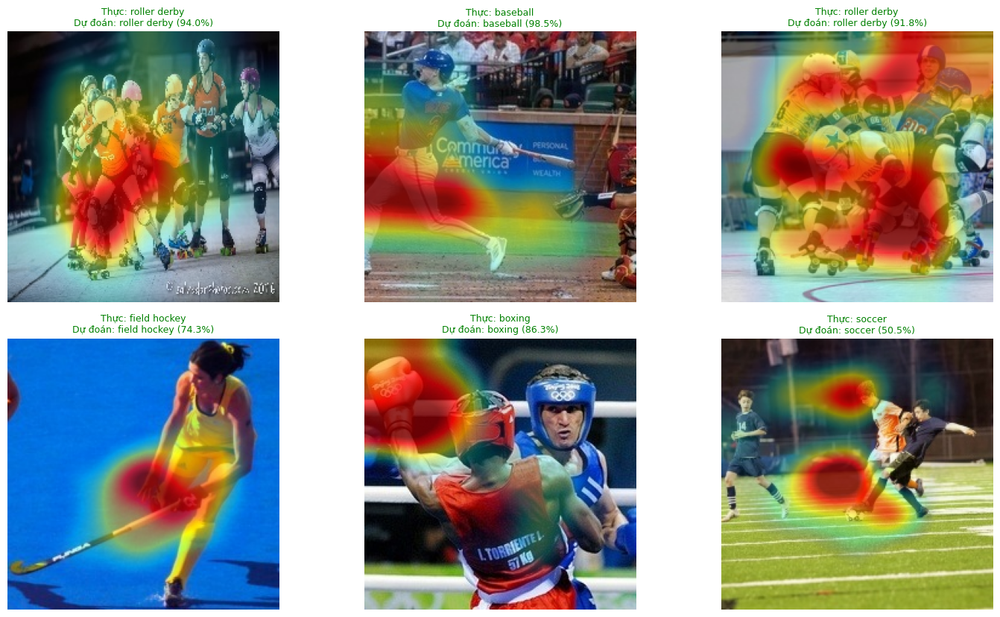

In [25]:
def show_gradcam_examples(model, ds_raw, preprocess_fn, class_names, n=6, seed=SEED):
    """Chọn ngẫu nhiên n ảnh test (test_ds_raw không shuffle nên take() chỉ ra vài ảnh đầu cùng 1 lớp)."""
    last_conv_name = get_last_conv_layer_name(model)
    all_imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    all_labels = np.concatenate([labels.numpy() for _, labels in ds_raw])
    chosen = np.random.RandomState(seed).choice(len(all_imgs), min(n, len(all_imgs)), replace=False)

    cols = max(1, math.ceil(len(chosen) / 2))
    rows = math.ceil(len(chosen) / cols)
    plt.figure(figsize=(5 * cols, 4.2 * rows))
    for k, idx in enumerate(chosen):
        img_rgb = all_imgs[idx].astype("uint8")
        x = tf.expand_dims(all_imgs[idx], 0)
        # CNN_Scratch đã có sẵn lớp Rescaling(1/255) bên trong -> KHÔNG chia 255 thêm lần nữa
        x = preprocess_fn(x) if preprocess_fn else x
        heatmap, pred_idx, pred_conf = make_gradcam_heatmap(x, model, last_conv_name, return_conf=True)
        overlay = overlay_gradcam(img_rgb, heatmap)

        plt.subplot(rows, cols, k + 1)
        plt.imshow(overlay)
        true_label = class_names[all_labels[idx]]
        pred_label = class_names[pred_idx]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"Thực: {true_label}\nDự đoán: {pred_label} ({pred_conf*100:.1f}%)", color=color, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

ensure_main_models_loaded(("mobilenet_model",))
print("Grad-CAM — MobileNetV2:")
show_gradcam_examples(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES, n=6)


Nhãn Grad-CAM khớp dự đoán mô hình: 32/32 (phải bằng nhau)
Grad-CAM — MobileNetV2 (mỗi lớp 1 ảnh):


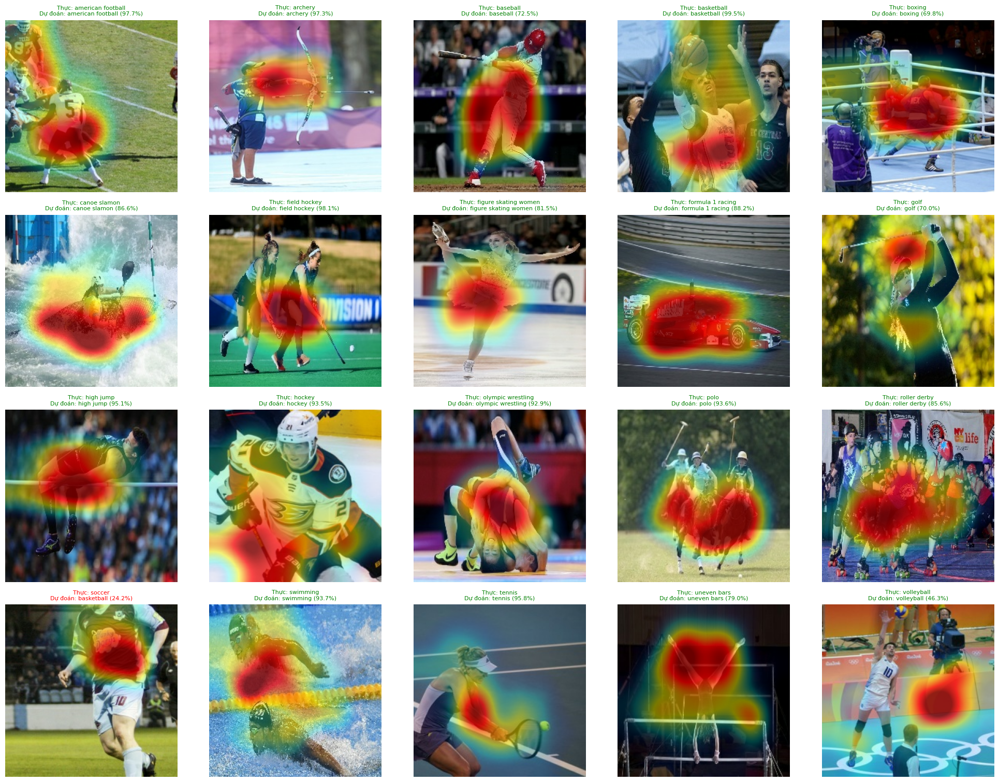

In [26]:
# Kiểm tra: nhãn dự đoán trong Grad-CAM phải KHỚP với dự đoán thật của mô hình
imgs, labs = next(iter(test_ds_raw))
n_check, n_match = 0, 0
for i in range(imgs.shape[0]):
    x = mnv2_preprocess(tf.expand_dims(imgs[i], 0))
    _, p_cam = make_gradcam_heatmap(x, mobilenet_model, get_last_conv_layer_name(mobilenet_model))
    p_true = int(np.argmax(mobilenet_model.predict(x, verbose=0)[0]))
    n_check += 1; n_match += int(p_cam == p_true)
print(f"Nhãn Grad-CAM khớp dự đoán mô hình: {n_match}/{n_check} (phải bằng nhau)")


def gradcam_one_per_class(model, ds_raw, preprocess_fn, class_names, cols=5):
    """Mỗi lớp lấy 1 ảnh (ảnh đầu tiên gặp trong tập test) để Grad-CAM đa dạng hơn."""
    name = get_last_conv_layer_name(model)
    seen, items = set(), []
    for images, labels in ds_raw:
        for i in range(images.shape[0]):
            y = int(labels[i])
            if y in seen:
                continue
            seen.add(y)
            items.append((images[i], y))
    items.sort(key=lambda t: t[1])
    rows = math.ceil(len(items) / cols)
    plt.figure(figsize=(4 * cols, 3.8 * rows))
    for k, (img, y) in enumerate(items):
        x = preprocess_fn(tf.expand_dims(img, 0)) if preprocess_fn else tf.expand_dims(img, 0)
        hm, p, conf = make_gradcam_heatmap(x, model, name, return_conf=True)
        ov = overlay_gradcam(img.numpy().astype("uint8"), hm)
        plt.subplot(rows, cols, k + 1)
        plt.imshow(ov)
        plt.axis("off")
        plt.title(f"Thực: {class_names[y]}\nDự đoán: {class_names[p]} ({conf*100:.1f}%)",
                  color="green" if p == y else "red", fontsize=8)
    plt.tight_layout()
    plt.show()


print("Grad-CAM — MobileNetV2 (mỗi lớp 1 ảnh):")
gradcam_one_per_class(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES)


Grad-CAM — các ảnh MobileNetV2 đoán sai:
Số ảnh test bị đoán sai: 17/500


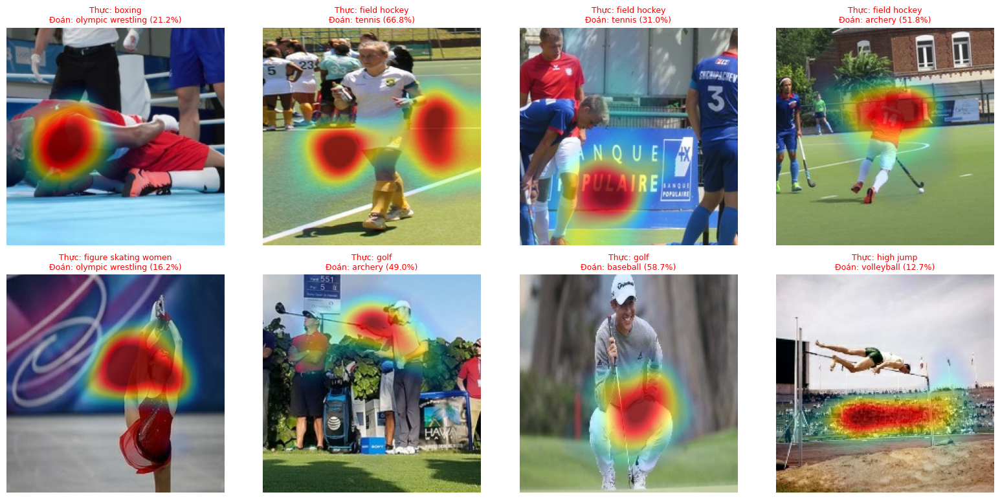

In [27]:
def gradcam_misclassified(model, ds_raw, preprocess_fn, class_names, max_show=8, cols=4):
    """Grad-CAM cho các ảnh test bị đoán SAI -> dùng cho phần phân tích lỗi trong báo cáo."""
    last_conv_name = get_last_conv_layer_name(model)
    imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    labs = np.concatenate([labels.numpy() for _, labels in ds_raw])
    x_all = preprocess_fn(tf.constant(imgs)) if preprocess_fn else tf.constant(imgs)
    preds = np.argmax(model.predict(x_all, batch_size=32, verbose=0), axis=1)
    wrong = np.where(preds != labs)[0]
    print(f"Số ảnh test bị đoán sai: {len(wrong)}/{len(labs)}")
    if len(wrong) == 0:
        return
    wrong = wrong[:max_show]
    rows = math.ceil(len(wrong) / cols)
    plt.figure(figsize=(4 * cols, 3.9 * rows))
    for k, idx in enumerate(wrong):
        x = tf.expand_dims(x_all[idx], 0)
        hm, p, conf = make_gradcam_heatmap(x, model, last_conv_name, return_conf=True)
        plt.subplot(rows, cols, k + 1)
        plt.imshow(overlay_gradcam(imgs[idx].astype("uint8"), hm))
        plt.axis("off")
        plt.title(f"Thực: {class_names[labs[idx]]}\nĐoán: {class_names[p]} ({conf*100:.1f}%)", color="red", fontsize=9)
    plt.tight_layout()
    plt.show()

print("Grad-CAM — các ảnh MobileNetV2 đoán sai:")
gradcam_misclassified(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES)


## 9. Lưu mô hình & kết luận

Mô hình tốt nhất (chọn theo **Validation Accuracy**, không chọn theo test để tránh "nhìn trộm" tập test) được lưu lại để dùng cho ứng dụng demo (web/mobile) phân loại môn thể thao từ ảnh chụp/tải lên.


In [28]:
ensure_main_models_loaded()
for m in (cnn_scratch, mobilenet_model, resnet_model):
    m.compile(optimizer="adam", loss=make_loss(), metrics=["accuracy"])


[SportSnap] Nạp cnn_scratch từ checkpoint: ./cnn_scratch_best.keras (epoch 42, val_loss=1.0589, val_acc=0.8767)
[SportSnap] Nạp resnet_model từ checkpoint: ./ResNet50_finetune_best.keras (epoch 20, val_loss=0.7371, val_acc=0.9800)


In [29]:
# Chọn mô hình tốt nhất theo VALIDATION accuracy (phá hòa bằng val_loss thấp hơn; không dùng tập test để chọn).
ensure_main_models_loaded()
val_pairs = {
    "CNN_Scratch": (cnn_scratch, valid_ds),
    "MobileNetV2": (mobilenet_model, valid_ds_mnv2),
    "ResNet50":    (resnet_model, valid_ds_res),
}
val_metrics = {n: m.evaluate(ds, verbose=0) for n, (m, ds) in val_pairs.items()}
val_loss = {n: float(v[0]) for n, v in val_metrics.items()}
val_acc  = {n: float(v[1]) for n, v in val_metrics.items()}

summary_df["Val Accuracy"] = summary_df["Mô hình"].map(val_acc).round(4)
summary_df["Val Loss"] = summary_df["Mô hình"].map(val_loss).round(4)

best_model_name = max(val_acc, key=lambda k: (val_acc[k], -val_loss[k]))
model_map = {"CNN_Scratch": cnn_scratch, "MobileNetV2": mobilenet_model, "ResNet50": resnet_model}
best_model = model_map[best_model_name]
best_model.save("sportsnap_best_model.keras", include_optimizer=False)

# Xuất thêm bản deploy nhẹ (< 50 MB cho Web App/Git theo AGENTS.md) và file labels.json chuẩn
mobilenet_model.save("MobileNetV2_deploy.keras", include_optimizer=False)
with open("labels.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False)
summary_df.to_csv("summary.csv", index=False, encoding="utf-8-sig")

EXPERIMENT_SUMMARY["val_accuracy"] = {k: round(float(v), 4) for k, v in val_acc.items()}
EXPERIMENT_SUMMARY["val_loss"] = {k: round(float(v), 4) for k, v in val_loss.items()}
EXPERIMENT_SUMMARY["selected_best_model"] = best_model_name

print(f"Đã lưu mô hình tốt nhất (theo Val): {best_model_name} -> sportsnap_best_model.keras ({os.path.getsize('sportsnap_best_model.keras')/1e6:.1f} MB)")
print(f"Đã lưu bản deploy Web App nhẹ (< 50 MB): MobileNetV2_deploy.keras ({os.path.getsize('MobileNetV2_deploy.keras')/1e6:.1f} MB)")
print(summary_df.to_string(index=False))


Đã lưu mô hình tốt nhất (theo Val): MobileNetV2 -> sportsnap_best_model.keras (9.7 MB)
Đã lưu bản deploy Web App nhẹ (< 50 MB): MobileNetV2_deploy.keras (9.7 MB)
    Mô hình  Test Accuracy  Đạt mục tiêu (>=0.88)  Val Accuracy  Val Loss
   ResNet50          0.978                   True        0.9800    0.7371
MobileNetV2          0.966                   True        0.9867    0.7702
CNN_Scratch          0.834                  False        0.8767    1.0589


In [30]:
# Nén toàn bộ file .keras và .epoch.json bằng zipfile chuẩn Python (chạy được trên cả Kaggle, Colab và Windows)
import zipfile
from IPython.display import FileLink, display

zip_targets = sorted(glob.glob("*.keras") + glob.glob("*.epoch.json"))
if zip_targets:
    with zipfile.ZipFile("models.zip", "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for fn in zip_targets:
            zf.write(fn, arcname=os.path.basename(fn))
    print(f"Đã nén {len(zip_targets)} tệp vào models.zip ({os.path.getsize('models.zip')/1e6:.1f} MB): {zip_targets}")
    display(FileLink("models.zip"))
else:
    print("Chưa tìm thấy tệp .keras nào trong thư mục hiện tại để nén.")


Đã nén 12 tệp vào models.zip (359.7 MB): ['MobileNetV2_deploy.keras', 'MobileNetV2_finetune_best.epoch.json', 'MobileNetV2_finetune_best.keras', 'MobileNetV2_head_best.epoch.json', 'MobileNetV2_head_best.keras', 'ResNet50_finetune_best.epoch.json', 'ResNet50_finetune_best.keras', 'ResNet50_head_best.epoch.json', 'ResNet50_head_best.keras', 'cnn_scratch_best.epoch.json', 'cnn_scratch_best.keras', 'sportsnap_best_model.keras']


/kaggle/working/models.zip

### Hàm dự đoán ảnh đơn (`predict_image`)

In [31]:
def predict_image(path, model, preprocess_fn, class_names, top_k=3, tta=True):
    """Dự đoán 1 ảnh: hiển thị ảnh + top_k nhãn (kèm xác suất) làm tiêu đề, trả về nhãn dự đoán.
    tta=True: lấy trung bình dự đoán của ảnh gốc và ảnh lật ngang (Test-Time Augmentation) cho ổn định hơn."""
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)   # tự chuyển về RGB 224x224
    arr = tf.keras.utils.img_to_array(img)
    batch = np.stack([arr, arr[:, ::-1, :]]) if tta else np.expand_dims(arr, 0)
    # CNN_Scratch (preprocess_fn=None) đã có Rescaling(1/255) bên trong -> KHÔNG chia 255 thêm lần nữa
    x = preprocess_fn(batch.copy()) if preprocess_fn else batch
    probs = model.predict(x, verbose=0).mean(axis=0)
    idx = np.argsort(probs)[::-1][:top_k]
    plt.figure()
    plt.imshow(img)
    plt.axis("off")
    plt.title("\n".join(f"{class_names[i]}: {probs[i] * 100:.1f}%" for i in idx))
    plt.show()
    return class_names[idx[0]]


Ảnh thật: golf | Đường dẫn: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification/test/golf/4.jpg


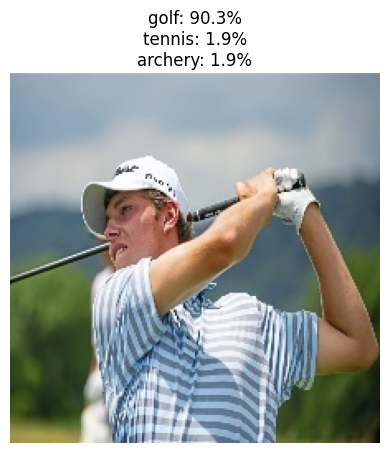

Dự đoán: golf


In [32]:
import random

# Chọn preprocess_fn tương ứng với best_model đã lưu (dựa theo summary_df)
preprocess_map = {
    "CNN_Scratch": None,
    "MobileNetV2": mnv2_preprocess,
    "ResNet50": resnet_preprocess,
}
best_preprocess_fn = preprocess_map[best_model_name]

# Lấy ngẫu nhiên 1 ảnh thật từ tập test để thử
sample_class = random.choice(CLASS_NAMES)
sample_files = glob.glob(os.path.join(TEST_DIR, sample_class, "*"))
sample_path = random.choice(sample_files)

print(f"Ảnh thật: {sample_class} | Đường dẫn: {sample_path}")
pred = predict_image(sample_path, best_model, best_preprocess_fn, CLASS_NAMES)
print("Dự đoán:", pred)

[SportSnap] Thư mục ảnh kiểm tra riêng: /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/anh-ngoai
[SportSnap] Tìm thấy 100 ảnh trong '/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/anh-ngoai'.
--- american football/1.jpg ---


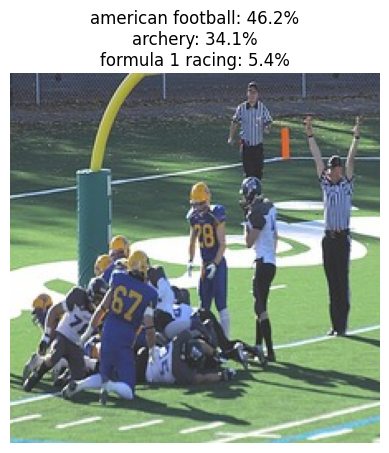

Dự đoán: american football
--- american football/2.jpg ---


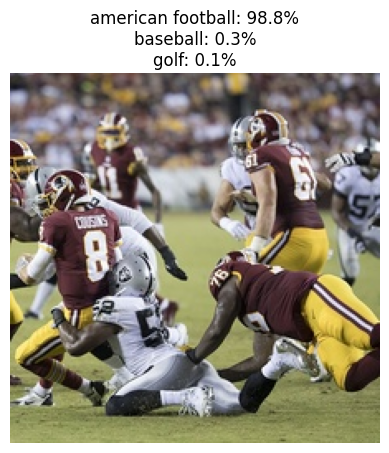

Dự đoán: american football
--- american football/3.jpg ---


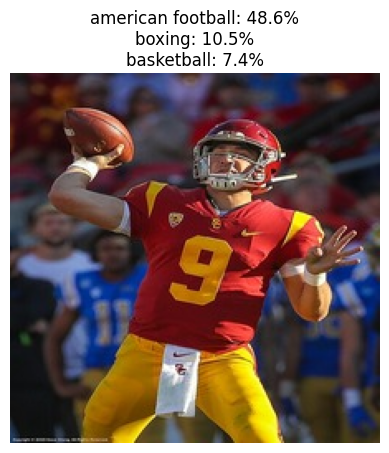

Dự đoán: american football
--- american football/4.jpg ---


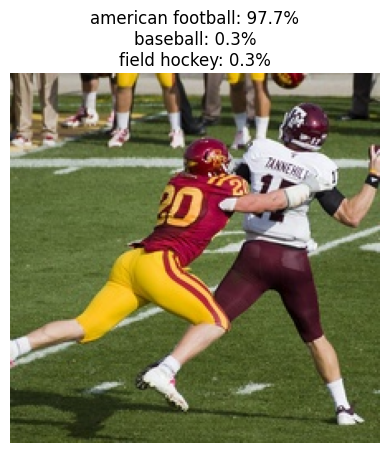

Dự đoán: american football
--- american football/5.jpg ---


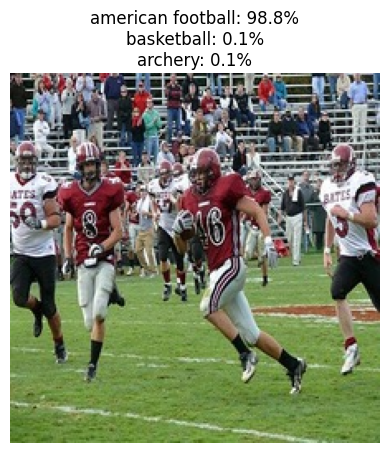

Dự đoán: american football
--- archery/1.jpg ---


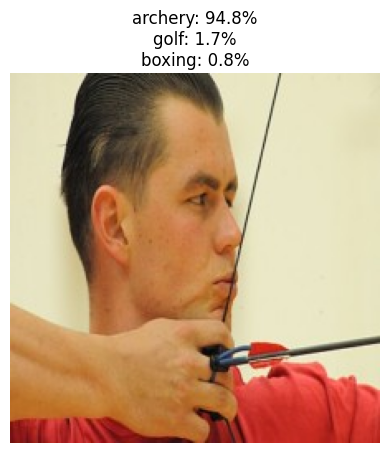

Dự đoán: archery
--- archery/2.jpg ---


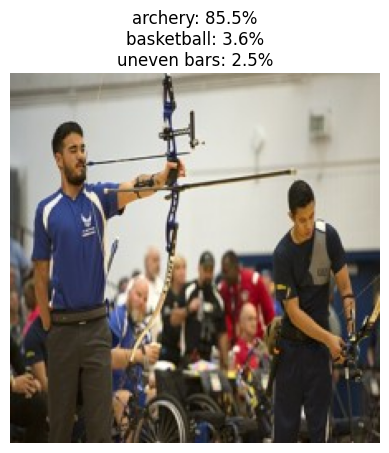

Dự đoán: archery
--- archery/3.jpg ---


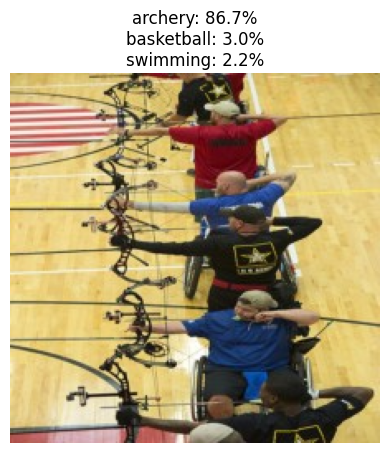

Dự đoán: archery
--- archery/4.jpg ---


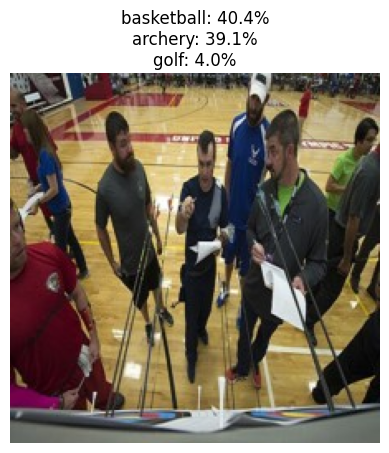

Dự đoán: basketball
--- archery/5.jpg ---


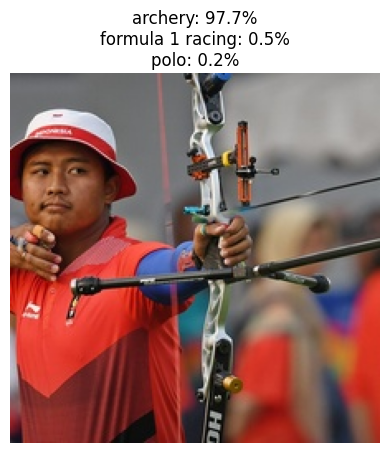

Dự đoán: archery
--- baseball/1.jpg ---


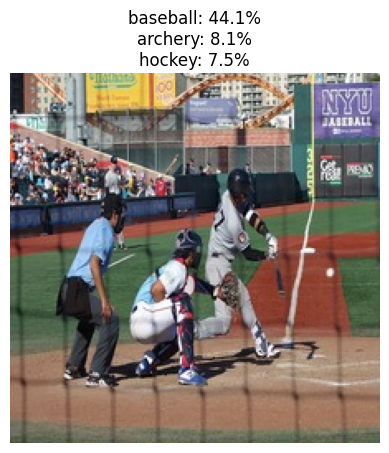

Dự đoán: baseball
--- baseball/2.jpg ---


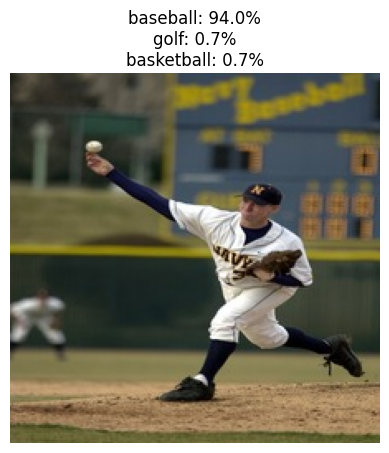

Dự đoán: baseball
--- baseball/3.jpg ---


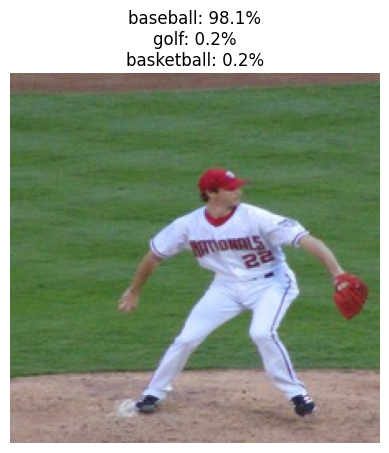

Dự đoán: baseball
--- baseball/4.jpg ---


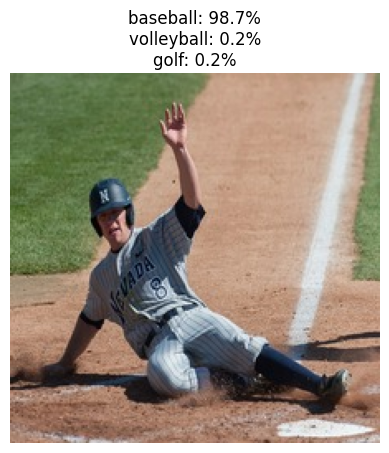

Dự đoán: baseball
--- baseball/5.jpg ---


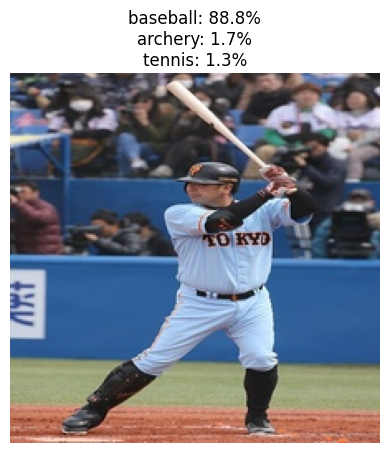

Dự đoán: baseball


In [33]:
import os

def auto_find_upload_dir():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "anh-ngoai" in dirs:
                return os.path.join(root, "anh-ngoai")
            if os.path.basename(root).lower() in ["anh-ngoai", "data123"]:
                return root
    cands = [
        r"d:\tgmt\datasets\anh-ngoai",
        r"../datasets/anh-ngoai",
        "/kaggle/input/anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/data123",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return cands[0]

UPLOAD_DIR = auto_find_upload_dir()
print(f"[SportSnap] Thư mục ảnh kiểm tra riêng: {UPLOAD_DIR}")

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if os.path.exists(UPLOAD_DIR):
    all_image_paths = []
    for root, _, files in os.walk(UPLOAD_DIR):
        for fname in sorted(files):
            if fname.lower().endswith(valid_extensions):
                all_image_paths.append(os.path.join(root, fname))
    
    print(f"[SportSnap] Tìm thấy {len(all_image_paths)} ảnh trong '{UPLOAD_DIR}'.")
    for path in all_image_paths[:15]:
        rel = os.path.relpath(path, UPLOAD_DIR)
        print(f"--- {rel} ---")
        pred = predict_image(path, best_model, best_preprocess_fn, CLASS_NAMES)
        print("Dự đoán:", pred)
else:
    print(f"Thư mục '{UPLOAD_DIR}' không tồn tại. Bỏ qua bước kiểm tra ảnh upload riêng.")


## 10. Hướng phát triển sau đồ án (tiến tới NCKH cấp Khoa)

- **Explainability nâng cao**: bổ sung phân tích SHAP bên cạnh Grad-CAM để so sánh và củng cố kết luận về đặc trưng thị giác quan trọng (màu sân, trang phục, dụng cụ...).
- **Mở rộng sang video**: áp dụng mô hình theo frame + tổng hợp theo temporal (vd. majority voting hoặc 3D-CNN/temporal pooling) để phân loại môn thể thao từ video thay vì ảnh tĩnh.
- **Viết báo cáo phân tích explainability** tổng hợp kết quả Grad-CAM/SHAP, phù hợp nộp NCKH cấp Khoa.
- **Triển khai demo**: đóng gói `sportsnap_best_model.keras` vào ứng dụng web (Streamlit/Flask) hoặc mobile (TensorFlow Lite) để chụp/tải ảnh và nhận kết quả phân loại trực tiếp.

**Từ khóa:** Sports Image Classification; Transfer Learning; CNN; MobileNetV2


## 11. Số liệu bổ sung: số tham số, kích thước mô hình, thời gian suy luận

In [34]:
# ==== Số liệu bổ sung cho báo cáo: số tham số, kích thước tệp, thời gian suy luận ====
import time

print("Số tham số:")
for n, m in model_map.items():
    print(f"  {n}: {m.count_params():,}")

size_mb = os.path.getsize("sportsnap_best_model.keras") / 1e6
print(f"Kích thước sportsnap_best_model.keras: {size_mb:.1f} MB")

x_dummy = tf.random.uniform((1, IMG_SIZE[0], IMG_SIZE[1], 3), 0, 255, dtype=tf.float32)
if best_preprocess_fn is not None:
    x_dummy = best_preprocess_fn(x_dummy)
for _ in range(10):
    best_model(x_dummy, training=False)          # khởi động (warm-up)
t0 = time.time()
for _ in range(50):
    best_model(x_dummy, training=False)
print(f"Thời gian suy luận trung bình: {(time.time() - t0) / 50 * 1000:.1f} ms/ảnh "
      f"(thiết bị: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'})")


Số tham số:
  CNN_Scratch: 646,548
  MobileNetV2: 2,283,604
  ResNet50: 23,628,692
Kích thước sportsnap_best_model.keras: 9.7 MB
Thời gian suy luận trung bình: 139.1 ms/ảnh (thiết bị: GPU)


In [35]:
OUT = "/kaggle/working/sportsnap_model" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\sportsnap_model"
os.makedirs(OUT, exist_ok=True)

shutil.copy2("sportsnap_best_model.keras", OUT)
if os.path.exists("MobileNetV2_deploy.keras"):
    shutil.copy2("MobileNetV2_deploy.keras", OUT)
with open(f"{OUT}/class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False)
with open(f"{OUT}/labels.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False)
summary_df.to_csv(f"{OUT}/summary.csv", index=False, encoding="utf-8-sig")

with open(f"{OUT}/dataset-metadata.json", "w", encoding="utf-8") as f:
    json.dump({
        "title": "SportSnap Model",
        "id": "kienmaitrung287/sportsnap-model",
        "licenses": [{"name": "CC0-1.0"}],
    }, f, ensure_ascii=False, indent=2)
print(f"Đã xuất artifacts model vào: {OUT}")


Đã xuất artifacts model vào: /kaggle/working/sportsnap_model


In [36]:
import os
search_root = "/kaggle/input" if os.path.exists("/kaggle/input") else r"d:\tgmt"
for root, dirs, files in os.walk(search_root):
    for f in files:
        if f.endswith((".keras", ".json")) and ("sportsnap" in (root + f).lower() or f.endswith(".keras")):
            print(os.path.join(root, f))


/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/class_weights.json


In [37]:
# Tùy chọn: đẩy nhanh artifacts lên Kaggle Dataset nếu đã cấu hình KAGGLE_KEY trong Kaggle Secrets
try:
    from kaggle_secrets import UserSecretsClient
    USERNAME = "kienmaitrung287"
    SLUG = "sportsnap-model"
    OUT = "/kaggle/working/sportsnap_model" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\sportsnap_model"

    assert os.path.exists("sportsnap_best_model.keras"), "Chưa có file model: hãy chạy cell lưu model trước"
    os.makedirs(OUT, exist_ok=True)
    shutil.copy2("sportsnap_best_model.keras", OUT)
    with open(f"{OUT}/class_names.json", "w", encoding="utf-8") as f:
        json.dump(CLASS_NAMES, f, ensure_ascii=False)
    summary_df.to_csv(f"{OUT}/summary.csv", index=False, encoding="utf-8-sig")
    with open(f"{OUT}/dataset-metadata.json", "w", encoding="utf-8") as f:
        json.dump({
            "title": "SportSnap Model",
            "id": f"{USERNAME}/{SLUG}",
            "licenses": [{"name": "CC0-1.0"}],
        }, f, ensure_ascii=False, indent=2)

    os.environ["KAGGLE_USERNAME"] = USERNAME
    os.environ["KAGGLE_KEY"] = UserSecretsClient().get_secret("KAGGLE_KEY")

    r = subprocess.run(["kaggle", "datasets", "create", "-p", OUT], capture_output=True, text=True)
    print(r.stdout, r.stderr)
    if "already" in (r.stdout + r.stderr).lower():
        r = subprocess.run(["kaggle", "datasets", "version", "-p", OUT, "-m", "cap nhat model"],
                           capture_output=True, text=True)
        print(r.stdout, r.stderr)
except Exception as e:
    print(f"[Bỏ qua đẩy Kaggle Secrets tự động]: {e}")


[Bỏ qua đẩy Kaggle Secrets tự động]: Connection error trying to communicate with service.


Found 6000 files belonging to 20 classes.
Found 300 files belonging to 20 classes.
Found 500 files belonging to 20 classes.
       so_anh  so_dung  accuracy
split                           
test      500      483    0.9660
train    6000     5945    0.9908
valid     300      296    0.9867
Đã lưu kết quả phân tích tất cả ảnh ra: /kaggle/working/ket_qua_du_doan_tat_ca_anh.csv

Tổng số ảnh sai: 76/6800
split                             file              thuc_te              du_doan  do_tin_cay        du_doan_thu_2
train  train/american football/083.jpg    american football             baseball   33.799999    american football
train         train/basketball/002.jpg           basketball             baseball   29.299999           basketball
train         train/basketball/003.jpg           basketball           volleyball   62.400002               tennis
train            train/boxing/w110.jpg               boxing           volleyball   28.000000           basketball
train            train/boxin

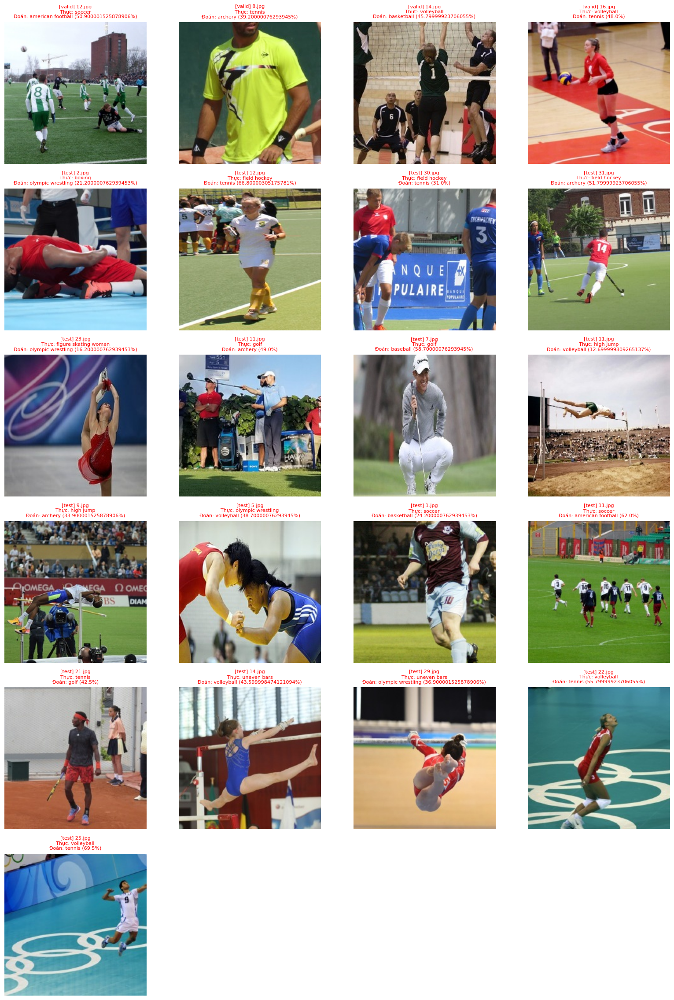

In [38]:
import math

def predict_all(model, preprocess_fn, directory, split_name):
    # shuffle=False nên thứ tự file_paths khớp với thứ tự dự đoán
    ds = make_filtered_dataset(directory, SELECTED_CLASSES, shuffle=False)
    paths = list(ds.file_paths)
    y_true = np.concatenate([y.numpy() for _, y in ds])
    ds_in = ds.map(lambda x, y: (preprocess_fn(x), y)) if preprocess_fn else ds
    probs = model.predict(ds_in, verbose=0)
    order = np.argsort(-probs, axis=1)
    top1, top2 = order[:, 0], order[:, 1]
    return pd.DataFrame({
        "split": split_name,
        "file": [os.path.relpath(p, DATA_ROOT) for p in paths],
        "path": paths,
        "thuc_te": [CLASS_NAMES[i] for i in y_true],
        "du_doan": [CLASS_NAMES[i] for i in top1],
        "do_tin_cay": (probs[np.arange(len(probs)), top1] * 100).round(1),
        "du_doan_thu_2": [CLASS_NAMES[i] for i in top2],
        "dung": top1 == y_true,
    })

# 1) Chạy trên TOÀN BỘ ảnh: train + valid + test
df_all = pd.concat(
    [predict_all(best_model, best_preprocess_fn, d, s)
     for s, d in [("train", TRAIN_DIR), ("valid", VALID_DIR), ("test", TEST_DIR)]],
    ignore_index=True)

# 2) Accuracy từng tập
summary = df_all.groupby("split")["dung"].agg(so_anh="count", so_dung="sum")
summary["accuracy"] = (summary["so_dung"] / summary["so_anh"]).round(4)
print(summary)

# 3) Lưu kết quả TẤT CẢ ảnh ra CSV (có thể tải về hoặc mở bằng Excel)
csv_out = "/kaggle/working/ket_qua_du_doan_tat_ca_anh.csv" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\ket_qua_du_doan_tat_ca_anh.csv"
os.makedirs(os.path.dirname(csv_out), exist_ok=True)
df_all.drop(columns="path").to_csv(csv_out, index=False, encoding="utf-8-sig")
if os.path.abspath(csv_out) != os.path.abspath("ket_qua_du_doan_tat_ca_anh.csv"):
    shutil.copy2(csv_out, "ket_qua_du_doan_tat_ca_anh.csv")
print(f"Đã lưu kết quả phân tích tất cả ảnh ra: {csv_out}")

# 4) Danh sách ảnh bị đoán sai (kèm tên file)
wrong_df = df_all[~df_all["dung"]]
print(f"\nTổng số ảnh sai: {len(wrong_df)}/{len(df_all)}")
print(wrong_df.drop(columns=["path", "dung"]).to_string(index=False))

# 5) Hiển thị ảnh sai của valid + test
def show_wrong(df, max_show=40, cols=4):
    df = df.head(max_show)
    if len(df) == 0:
        print("Không có ảnh sai nào.")
        return
    rows = math.ceil(len(df) / cols)
    plt.figure(figsize=(4 * cols, 3.8 * rows))
    for k, r in enumerate(df.itertuples()):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(tf.keras.utils.load_img(r.path, target_size=IMG_SIZE))
        plt.axis("off")
        plt.title(f"[{r.split}] {os.path.basename(r.file)}\nThực: {r.thuc_te}\n"
                  f"Đoán: {r.du_doan} ({r.do_tin_cay}%)", color="red", fontsize=8)
    plt.tight_layout()
    plt.show()

show_wrong(wrong_df[wrong_df["split"] != "train"])


1
               file thuc_te du_doan  do_tin_cay
train/golf/w059.jpg    golf archery   82.599998


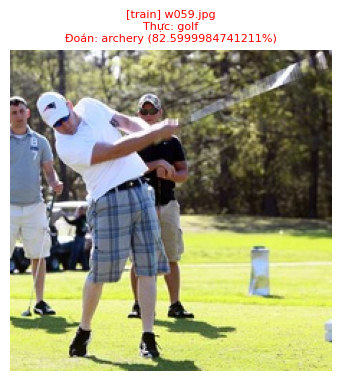

In [39]:
sus = df_all[(df_all.split == "train") & (~df_all.dung) & (df_all.do_tin_cay >= 80)]
print(len(sus))
print(sus[["file", "thuc_te", "du_doan", "do_tin_cay"]].to_string(index=False))
show_wrong(sus, max_show=24)

## 12. Các thí nghiệm bổ sung & kiểm chứng nâng cao (Mục 5.9)

Gộp toàn bộ thí nghiệm từ `detainhom_bosung.ipynb` để phục vụ điền số liệu Bảng 5.10 và phân tích sâu:
- Các mục **12.1, 12.2** sử dụng trực tiếp `train_transfer_model`, `build_cnn_scratch` (từ Mục 5–6) và cờ `RUN_*` ở Mục 2.
- Các mục **12.3–12.7** tự động dùng model đang có trong bộ nhớ (nếu vừa chạy Mục 6–9) hoặc nạp từ checkpoint `.keras` đã lưu (`all_sportsnap_outputs/`, `notebook/`, `backend/models/`). Nếu chạy nhảy cóc chỉ các mục đánh giá nhanh này, hãy chạy trước tối thiểu Mục **1, 2, 4 và 8**.

In [40]:
# ==== HÀM HỖ TRỢ DÙNG CHUNG CHO MỤC 12 ====
def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

def eval_ds(model, ds_raw, pre=None):
    ds = prep_dataset(ds_raw, augment=False, preprocess_fn=pre, cache=False)
    y = np.concatenate([b.numpy() for _, b in ds_raw])
    p = np.argmax(model.predict(ds, verbose=0), axis=1)
    return accuracy_score(y, p), f1_score(y, p, average="macro")

def detect_model_preprocess(model):
    """Tự nhận diện hàm tiền xử lý khớp với kiến trúc model được nạp từ đĩa."""
    names = " ".join([getattr(model, "name", "")] + [l.name for l in model.layers]).lower()
    if "resnet" in names:
        return resnet_preprocess, "ResNet50"
    if "mobilenet" in names:
        return mnv2_preprocess, "MobileNetV2"
    return None, "CNN_Scratch"

def resolve_model_path(filenames):
    search_dirs = [".", "/kaggle/working"]
    if globals().get("MODEL_DIR"):
        search_dirs.append(MODEL_DIR)
    search_dirs.extend([
        r"d:\tgmt\all_sportsnap_outputs",
        r"../all_sportsnap_outputs",
        r"d:\tgmt\notebook",
        r"d:\tgmt\backend\models",
        r"../backend/models",
    ])
    for d in dict.fromkeys(search_dirs):
        if not d:
            continue
        for fn in filenames:
            p = os.path.join(d, fn)
            if os.path.exists(p):
                return p
    return None

def get_or_load_best_model():
    if "best_model" in globals() and globals()["best_model"] is not None:
        m = globals()["best_model"]
        pre = globals()["best_preprocess_fn"] if "best_preprocess_fn" in globals() else detect_model_preprocess(m)[0]
        name = globals().get("best_model_name", detect_model_preprocess(m)[1])
        return m, pre, name

    p = resolve_model_path(["sportsnap_best_model.keras", "best_model.keras", "MobileNetV2_finetune_best.keras"])
    if p is None:
        raise FileNotFoundError("Không tìm thấy file model đã lưu (sportsnap_best_model.keras / best_model.keras).")
    m = load_model_with_epoch(p, var_name="best_model", compile=False)
    pre, arch_name = detect_model_preprocess(m)
    return m, pre, f"{arch_name} (loaded)"

def get_or_load_named_model(var_name, checkpoint_filenames, require_history_key=None):
    has_trained = True
    if require_history_key is not None:
        has_trained = "histories" in globals() and require_history_key in globals()["histories"]
    if has_trained and var_name in globals() and globals()[var_name] is not None:
        return globals()[var_name]
    p = resolve_model_path(checkpoint_filenames)
    if p is not None:
        return load_model_with_epoch(p, var_name=var_name, compile=False)
    return None


### 12.1. Lặp nhiều hạt giống (MobileNetV2: 5 seed; ResNet50: 3 seed; CNN_Scratch: 5 seed)

In [41]:
# Tự dò thư mục chứa checkpoint .keras (hỗ trợ cả Kaggle /kaggle/input, /kaggle/working và máy local)
def auto_find_model_dir():
    for root_cand in [".", "/kaggle/working", r"d:\tgmt\all_sportsnap_outputs", r"../all_sportsnap_outputs"]:
        if os.path.exists(os.path.join(root_cand, "MobileNetV2_finetune_best.keras")):
            return root_cand
    if os.path.exists("/kaggle/input"):
        hits = glob.glob("/kaggle/input/**/MobileNetV2_finetune_best.keras", recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    return "."

MODEL_DIR = auto_find_model_dir()
print(f"[SportSnap] MODEL_DIR: {MODEL_DIR}")


[SportSnap] MODEL_DIR: .


In [42]:
# Khôi phục các mô hình nếu chưa có trong bộ nhớ (không ghi đè lịch sử train nếu vừa chạy Mục 6)
cnn_scratch     = get_or_load_named_model("cnn_scratch", ["cnn_scratch_best.keras"])
mobilenet_model = get_or_load_named_model("mobilenet_model", ["MobileNetV2_finetune_best.keras"])
resnet_model    = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])

test_ds       = prep_dataset(test_ds_raw, augment=False)
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
test_ds_res   = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds      = prep_dataset(valid_ds_raw, augment=False, onehot=True)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)
valid_ds_res  = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

if "head_only_acc" not in globals():
    head_only_acc = {}
for name, ds in [("MobileNetV2", test_ds_mnv2), ("ResNet50", test_ds_res)]:
    if name not in head_only_acc:
        p_head = resolve_model_path([f"{name}_head_best.keras"])
        if p_head is not None:
            m_head = load_model_with_epoch(p_head, var_name=f"{name}_head", compile=False)
            head_only_acc[name] = quick_acc(m_head, ds)
            del m_head
print("Head-only accuracy:", head_only_acc)


Head-only accuracy: {'MobileNetV2': 0.916, 'ResNet50': 0.942}


In [43]:
if RUN_MULTI_SEED:
    # Đồng bộ lại dataset để mỗi seed không dùng nhầm iterator cũ
    ms_train_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    CFG_SEEDS = {
        "MobileNetV2": (MobileNetV2, mnv2_preprocess, 5),
        "ResNet50":    (ResNet50, resnet_preprocess, 3),
    }
    multi_seed_res = {}
    for name, (cls, pre, n_seed) in CFG_SEEDS.items():
        multi_seed_res[name] = []
        for s in range(n_seed):
            set_seed(100 + s)
            m, *_ = train_transfer_model(
                cls, pre, f"{name}_s{s}",
                ms_train_raw, ms_valid_raw, UNFREEZE[name],
                checkpoint=False,
                epochs_head=SUPP_EPOCHS_HEAD,
                epochs_ft=SUPP_EPOCHS_FT,
                cache_train=False,
                verbose=0,
            )
            acc, f1 = eval_ds(m, ms_test_raw, pre)
            multi_seed_res[name].append((acc, f1))
            print(f"{name} seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
            del m
            safe_clear_session(reset_globals=True)

    for k, v in multi_seed_res.items():
        a = np.array(v)
        print(
            f"{k}: acc {a[:,0].mean():.3f} ± {a[:,0].std(ddof=1):.3f} "
            f"(min {a[:,0].min():.2f}, max {a[:,0].max():.2f}) | "
            f"F1 {a[:,1].mean():.3f} ± {a[:,1].std(ddof=1):.3f}"
        )
        EXPERIMENT_SUMMARY.setdefault("multi_seed", {})[k] = {
            "acc_mean": round(float(a[:,0].mean()), 4), "acc_std": round(float(a[:,0].std(ddof=1)), 4),
            "f1_mean": round(float(a[:,1].mean()), 4), "f1_std": round(float(a[:,1].std(ddof=1)), 4),
            "runs": [[round(float(r[0]), 4), round(float(r[1]), 4)] for r in v],
        }
else:
    print("RUN_MULTI_SEED = False -> bỏ qua thí nghiệm lặp nhiều hạt giống. Bật RUN_MULTI_SEED = True ở mục 2 để chạy.")

Found 6000 files belonging to 20 classes.
Found 300 files belonging to 20 classes.
Found 500 files belonging to 20 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


#### CNN_Scratch (5 seed, mỗi seed 50 epoch)
Dùng lại kiến trúc `build_cnn_scratch` và lịch cosine LR của Mục 6 với `set_seed(100 + s)` (bật `RUN_MULTI_SEED = True` và `RUN_MULTI_SEED_CNN = True` ở Mục 2 để chạy).

In [ ]:
if RUN_MULTI_SEED and RUN_MULTI_SEED_CNN:
    ms_train_raw = globals().get("ms_train_raw") if globals().get("ms_train_raw") is not None else make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = globals().get("ms_valid_raw") if globals().get("ms_valid_raw") is not None else make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = globals().get("ms_test_raw")  if globals().get("ms_test_raw") is not None else make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    n_epochs_cnn = globals().get("EPOCHS_SCRATCH", 50)
    cnn_seed_res = []
    for s in range(5):
        set_seed(100 + s)
        m_cnn = build_cnn_scratch(INPUT_SHAPE, NUM_CLASSES)
        tr_c = prep_dataset(ms_train_raw, augment=True, cache=False, onehot=True)
        va_c = prep_dataset(ms_valid_raw, augment=False, onehot=True)
        m_cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
        m_cnn.fit(
            tr_c, validation_data=va_c, epochs=n_epochs_cnn, verbose=0,
            callbacks=get_callbacks(
                f"cnn_scratch_s{s}", checkpoint=False, plateau=False,
                lr_fn=cosine_schedule(1e-3, n_epochs_cnn, min_lr=1e-6, warmup_epochs=2),
                patience=12,
            ),
        )
        acc, f1 = eval_ds(m_cnn, ms_test_raw, None)
        cnn_seed_res.append((acc, f1))
        print(f"CNN_Scratch seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
        del m_cnn, tr_c, va_c
        safe_clear_session(reset_globals=True)

    a_cnn = np.array(cnn_seed_res)
    print(
        f"CNN_Scratch: acc {a_cnn[:,0].mean():.3f} ± {a_cnn[:,0].std(ddof=1):.3f} "
        f"(min {a_cnn[:,0].min():.2f}, max {a_cnn[:,0].max():.2f}) | "
        f"F1 {a_cnn[:,1].mean():.3f} ± {a_cnn[:,1].std(ddof=1):.3f}"
    )
    EXPERIMENT_SUMMARY.setdefault("multi_seed", {})["CNN_Scratch"] = {
        "acc_mean": round(float(a_cnn[:,0].mean()), 4), "acc_std": round(float(a_cnn[:,0].std(ddof=1)), 4),
        "f1_mean": round(float(a_cnn[:,1].mean()), 4), "f1_std": round(float(a_cnn[:,1].std(ddof=1)), 4),
        "runs": [[round(float(r[0]), 4), round(float(r[1]), 4)] for r in cnn_seed_res],
    }
else:
    print("Bỏ qua CNN_Scratch multi-seed (cần bật cả RUN_MULTI_SEED = True và RUN_MULTI_SEED_CNN = True ở mục 2).")

### 12.2. Tập test mở rộng (20% train, phân tầng); huấn luyện trên 80% còn lại

In [ ]:
if RUN_EXTENDED_TEST:
    ext_paths, ext_labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        fs = sorted(
            f for f in glob.glob(os.path.join(TRAIN_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        ext_paths += fs
        ext_labels += [i] * len(fs)

    p_tr, p_te, y_tr, y_te = train_test_split(
        ext_paths, ext_labels, test_size=0.2, stratify=ext_labels, random_state=SEED
    )
    print(f"Chia phân tầng từ train -> Train 80%: {len(p_tr)} ảnh | Test mở rộng 20%: {len(p_te)} ảnh")

    def to_ds(paths_list, labels_list, shuffle=False):
        def load(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y
        ds = tf.data.Dataset.from_tensor_slices((paths_list, labels_list)).map(load, num_parallel_calls=AUTOTUNE)
        if shuffle:
            ds = ds.shuffle(len(paths_list), seed=SEED)
        return ds.batch(BATCH_SIZE)

    tr80, te20 = to_ds(p_tr, y_tr, True), to_ds(p_te, y_te, False)
    set_seed(SEED)
    m_ext, *_ = train_transfer_model(
        MobileNetV2, mnv2_preprocess, "MNV2_ext",
        tr80, valid_ds_raw, UNFREEZE["MobileNetV2"],
        checkpoint=False,
        epochs_head=SUPP_EPOCHS_HEAD,
        epochs_ft=SUPP_EPOCHS_FT,
        cache_train=False,
        verbose=0,
    )
    acc, f1 = eval_ds(m_ext, te20, mnv2_preprocess)
    n_te, z = len(y_te), 1.96
    lo = (acc + z*z/(2*n_te) - z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    hi = (acc + z*z/(2*n_te) + z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    print(f"Test mở rộng n={n_te}: acc {acc:.3f} | F1 {f1:.3f} | Wilson 95% CI [{lo:.3f}; {hi:.3f}]")
    del m_ext, tr80, te20
    EXPERIMENT_SUMMARY["extended_test_20pct"] = {
        "n": int(n_te), "acc": round(float(acc), 4), "macro_f1": round(float(f1), 4),
        "wilson_95_ci": [round(float(lo), 4), round(float(hi), 4)],
    }
    safe_clear_session(reset_globals=True)
else:
    print("RUN_EXTENDED_TEST = False -> bỏ qua thí nghiệm tập test mở rộng. Bật RUN_EXTENDED_TEST = True ở mục 2 để chạy.")

### 12.3. Kiểm tra trùng ảnh bằng pHash (test/valid so với train, 20 lớp)
Phát hiện các cặp gần trùng (khoảng cách Hamming ≤ 5), tạo tập `bad_test`, loại bỏ khỏi tập test và đánh giá lại mô hình tốt nhất đã lưu.

In [ ]:
if RUN_PHASH_CHECK:
    try:
        import imagehash

        def compute_hashes(directory):
            items = []
            for c in CLASS_NAMES:
                for f in sorted(glob.glob(os.path.join(directory, c, "*"))):
                    if f.lower().endswith(VALID_IMAGE_EXTS):
                        with Image.open(f) as im:
                            items.append((f, c, imagehash.phash(im.convert("RGB"))))
            return items

        H_tr = compute_hashes(TRAIN_DIR)
        H_te = compute_hashes(TEST_DIR)
        H_va = compute_hashes(VALID_DIR)

        near = [
            (nm, f, f2, int(h - h2))
            for nm, H in [("test", H_te), ("valid", H_va)]
            for f, c, h in H
            for f2, c2, h2 in H_tr
            if (h - h2) <= 5
        ]
        print("Số cặp gần trùng (Hamming ≤ 5):", len(near))
        for x in near[:30]:
            print(" ", x)

        bad_test = {os.path.abspath(f) for nm, f, _, _ in near if nm == "test"}
        print("Số ảnh test bị trùng với train:", len(bad_test))

        # Loại bad_test khỏi tập test và đánh giá lại mô hình đã lưu
        eval_best_m, eval_best_pre, eval_best_name = get_or_load_best_model()
        clean_paths, clean_labels = [], []
        for ci, cname in enumerate(CLASS_NAMES):
            for f in sorted(glob.glob(os.path.join(TEST_DIR, cname, "*"))):
                if f.lower().endswith(VALID_IMAGE_EXTS) and os.path.abspath(f) not in bad_test:
                    clean_paths.append(f)
                    clean_labels.append(ci)

        def _load_clean(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y

        clean_ds = tf.data.Dataset.from_tensor_slices((clean_paths, clean_labels)).map(
            _load_clean, num_parallel_calls=AUTOTUNE
        ).batch(BATCH_SIZE)
        clean_acc, clean_f1 = eval_ds(eval_best_m, clean_ds, eval_best_pre)
        print(
            f"Đánh giá lại {eval_best_name} trên tập test sạch "
            f"(loại {len(bad_test)} ảnh trùng, còn n={len(clean_paths)}): "
            f"Accuracy = {clean_acc:.4f} | Macro-F1 = {clean_f1:.4f}"
        )
        EXPERIMENT_SUMMARY["phash_check"] = {
            "near_pairs_le_5": int(len(near)), "bad_test_removed": int(len(bad_test)),
            "clean_test_n": int(len(clean_paths)), "clean_acc": round(float(clean_acc), 4),
            "clean_macro_f1": round(float(clean_f1), 4),
        }
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.3]: Chưa cài thư viện 'imagehash' ({e}). Cài bằng: pip install imagehash")
else:
    print("RUN_PHASH_CHECK = False -> bỏ qua kiểm tra pHash.")

### 12.4. Ảnh ngoài bộ dữ liệu + Top-1 / Top-5
Đặt ảnh vào `EXT_DIR/<tên_lớp>/*.jpg` (khoảng 5 ảnh mỗi lớp, ghi nguồn riêng). Khác với phần hiển thị trực quan ở Mục 9, mục này tính chỉ số định lượng Top-1 / Top-5 trên toàn bộ tập ảnh ngoài.

In [ ]:
def auto_find_ext_dir():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "anh-ngoai" in dirs:
                return os.path.join(root, "anh-ngoai")
            if os.path.basename(root).lower() == "anh-ngoai":
                return root
    cands = [
        r"d:\tgmt\datasets\anh-ngoai",
        r"../datasets/anh-ngoai",
        "/kaggle/input/sportsnap-clean-6900/anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return cands[0]

EXT_DIR = auto_find_ext_dir()
print("[SportSnap] EXT_DIR:", EXT_DIR)

if os.path.exists(EXT_DIR):
    ext_model, ext_pre, ext_name = get_or_load_best_model()
    print(f"[SportSnap] Đánh giá bằng mô hình: {ext_name}")
    top1 = top5 = n_ext = 0
    for i, c in enumerate(CLASS_NAMES):
        files = sorted(
            f for f in glob.glob(os.path.join(EXT_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        for f in files:
            img = tf.image.resize(
                tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False),
                IMG_SIZE,
            )
            x_in = tf.expand_dims(img, 0)
            if ext_pre is not None:
                x_in = ext_pre(x_in)
            pr = ext_model(x_in, training=False).numpy()[0]
            order = np.argsort(pr)[::-1]
            top1 += int(order[0] == i)
            top5 += int(i in order[:5])
            n_ext += 1
    print("Hoàn tất đánh giá trên ảnh ngoài (Unseen dataset):")
    print(
        f"Tổng số ảnh kiểm tra n = {n_ext} | "
        f"Top-1 Accuracy: {top1/max(n_ext,1):.3f} ({top1}/{n_ext}) | "
        f"Top-5 Accuracy: {top5/max(n_ext,1):.3f} ({top5}/{n_ext})"
    )
    EXPERIMENT_SUMMARY["anh_ngoai"] = {
        "model": ext_name, "n": int(n_ext),
        "top1": round(float(top1 / max(n_ext, 1)), 4), "top1_correct": int(top1),
        "top5": round(float(top5 / max(n_ext, 1)), 4), "top5_correct": int(top5),
    }
else:
    print(f"Lưu ý: Thư mục ảnh ngoài '{EXT_DIR}' chưa tồn tại trên máy. Bạn có thể tạo thư mục này để thử nghiệm.")

### 12.5. Thời gian suy luận trên CPU (batch 1, 100 lần, bỏ 10 lần khởi động) và kích thước tệp

In [ ]:
def cpu_time(model_path, pre, var_name):
    x = tf.random.uniform((1, IMG_SIZE[0], IMG_SIZE[1], 3), 0, 255)
    if pre is not None:
        x = pre(x)
    # Nạp trọng số NGAY BÊN TRONG /CPU:0 để trên Kaggle GPU không bị đặt nhầm trọng số lên /GPU:0
    with tf.device("/CPU:0"):
        m_cpu = load_model_with_epoch(model_path, var_name=var_name, compile=False)
        for _ in range(10):
            m_cpu(x, training=False)
        t0 = time.time()
        for _ in range(100):
            m_cpu(x, training=False)
        ms = (time.time() - t0) / 100 * 1000
    del m_cpu
    return ms

bench_specs = [
    ("MobileNetV2", mnv2_preprocess, ["MobileNetV2_deploy.keras", "MobileNetV2_finetune_best.keras", "sportsnap_best_model.keras", "best_model.keras"]),
    ("ResNet50",    resnet_preprocess, ["ResNet50_finetune_best.keras"]),
    ("CNN_Scratch", None, ["cnn_scratch_best.keras"]),
]

cpu_bench_summary = {}
ran_any_bench = False
for name, pre, cands in bench_specs:
    f = resolve_model_path(cands)
    if f is not None:
        ms = cpu_time(f, pre, name)
        size_mb = os.path.getsize(f) / 1e6
        print(f"  -> {name}: {ms:.1f} ms/ảnh (CPU) | {size_mb:.1f} MB")
        cpu_bench_summary[name] = {"file": os.path.basename(f), "cpu_ms": round(float(ms), 2), "size_mb": round(float(size_mb), 2)}
        safe_clear_session(reset_globals=True)
        ran_any_bench = True
    else:
        print(f"{name}: Chưa tìm thấy file checkpoint ({', '.join(cands)}).")

EXPERIMENT_SUMMARY["cpu_benchmark"] = cpu_bench_summary


### 12.6. Ablation che nền / che người (RQ2)
Mặt nạ người từ DeepLabV3 trên tập valid+test; ba phiên bản (gốc / chỉ nền / chỉ người; vùng bị che tô xám) và tỷ lệ năng lượng Grad-CAM nằm trong mặt nạ người.

In [ ]:
if RUN_ABLATION:
    try:
        import torch
        from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

        ab_target = globals().get("ABLATION_MODEL", "best")
        if ab_target == "ResNet50":
            ab_model = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])
            ab_pre, ab_name = resnet_preprocess, "ResNet50"
        elif ab_target == "MobileNetV2":
            ab_model = get_or_load_named_model("mobilenet_model", ["MobileNetV2_finetune_best.keras"])
            ab_pre, ab_name = mnv2_preprocess, "MobileNetV2"
        else:
            ab_model, ab_pre, ab_name = get_or_load_best_model()

        if ab_model is None:
            raise FileNotFoundError(f"Không tìm thấy checkpoint cho mô hình Ablation ({ab_target}).")

        last_conv_ab = get_last_conv_layer_name(ab_model)
        torch_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"[SportSnap] Chạy DeepLabV3 trên thiết bị: {torch_dev} | Mô hình phân loại: {ab_name}")
        seg = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT).to(torch_dev).eval()
        tf_seg = DeepLabV3_ResNet50_Weights.DEFAULT.transforms()

        def person_mask(pil_img):
            with torch.no_grad():
                inp = tf_seg(pil_img).unsqueeze(0).to(torch_dev)
                out = seg(inp)["out"][0].argmax(0).cpu().numpy()
            return np.array(
                Image.fromarray(((out == 15) * 255).astype("uint8")).resize(IMG_SIZE, Image.NEAREST)
            ) > 0

        rows = []
        eval_dirs = list(dict.fromkeys([d for d in (VALID_DIR, TEST_DIR) if d]))
        for d in eval_dirs:
            for i, c in enumerate(CLASS_NAMES):
                for f in sorted(glob.glob(os.path.join(d, c, "*"))):
                    if not f.lower().endswith(VALID_IMAGE_EXTS):
                        continue
                    with Image.open(f) as raw_im:
                        pil = raw_im.convert("RGB")
                        o = np.array(pil.resize(IMG_SIZE)).astype("float32")
                        m = person_mask(pil)[..., None]
                    batch3 = np.stack([o, np.where(m, 127.0, o), np.where(m, o, 127.0)], axis=0)
                    vx_batch = ab_pre(batch3.copy()) if ab_pre is not None else batch3
                    probs3 = ab_model(vx_batch, training=False).numpy()
                    preds = [int(np.argmax(probs3[k])) for k in range(3)]
                    ox = tf.expand_dims(vx_batch[0], 0)
                    heat, _ = make_gradcam_heatmap(ox, ab_model, last_conv_ab)
                    h = cv2.resize(heat, IMG_SIZE, interpolation=cv2.INTER_CUBIC)
                    h = np.clip(h, 0.0, 1.0)
                    rows.append((c, i, *preds, float((h * m[..., 0]).sum() / (h.sum() + 1e-8))))

        df_ab = pd.DataFrame(rows, columns=["cls", "y", "orig", "bg_only", "person_only", "gradcam_in_person"])
        df_ab["orig_ok"] = df_ab["orig"] == df_ab["y"]
        df_ab["bg_ok"] = df_ab["bg_only"] == df_ab["y"]
        df_ab["person_ok"] = df_ab["person_only"] == df_ab["y"]

        acc_orig = float(df_ab["orig_ok"].mean())
        acc_bg = float(df_ab["bg_ok"].mean())
        acc_person = float(df_ab["person_ok"].mean())
        gc_in_person = float(df_ab["gradcam_in_person"].mean())

        print(
            f"Ablation ({ab_name}, n={len(df_ab)}): "
            f"Acc gốc {acc_orig:.3f} | chỉ nền {acc_bg:.3f} | chỉ người {acc_person:.3f}"
        )
        print(df_ab.groupby("cls")[["orig_ok", "bg_ok", "person_ok"]].mean().round(3))
        print(f"Tỷ lệ năng lượng Grad-CAM trong mặt nạ người (TB): {gc_in_person:.3f}")

        EXPERIMENT_SUMMARY["ablation_deeplabv3"] = {
            "model": ab_name, "n": int(len(df_ab)),
            "acc_orig": round(acc_orig, 4), "acc_bg_only": round(acc_bg, 4),
            "acc_person_only": round(acc_person, 4), "gradcam_in_person_mean": round(gc_in_person, 4),
        }

        # Giải phóng VRAM PyTorch trước khi chạy Cell Grad-CAM so sánh 3 kiến trúc
        del seg
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.6]: Cần cài đặt 'torch' và 'torchvision' để chạy phần phân tách mặt nạ người DeepLabV3 ({e}).")
else:
    print("RUN_ABLATION = False -> bỏ qua Ablation che nền / che người. Bật RUN_ABLATION = True ở Mục 2 để chạy.")


### 12.7. Grad-CAM cho ResNet50 và CNN_Scratch
Dùng lại `show_gradcam_examples` của Mục 4 với mô hình đã khôi phục ở Mục 5 (hoặc tự nạp từ checkpoint nếu chưa chạy Mục 5) và cùng `seed=SEED`.

In [ ]:
# Khôi phục 3 mô hình để đối chiếu Grad-CAM
m_cnn_cam = get_or_load_named_model("cnn_scratch", ["cnn_scratch_best.keras"])
m_mnv2_cam = get_or_load_named_model("mobilenet_model", ["MobileNetV2_finetune_best.keras"])
m_res_cam = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])


def compare_gradcam_models_side_by_side(models_spec, ds_raw, class_names, n=5, seed=SEED):
    """So sánh trực tiếp Grad-CAM của nhiều kiến trúc trên CÙNG một bức ảnh test
    (Ảnh gốc | CNN_Scratch | MobileNetV2 | ResNet50) — phục vụ trực tiếp Câu hỏi nghiên cứu chính."""
    active_specs = [(title, mdl, prep) for title, mdl, prep in models_spec if mdl is not None]
    if not active_specs:
        print("Chưa có mô hình nào khả dụng để so sánh Grad-CAM.")
        return

    all_imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    all_labels = np.concatenate([labels.numpy() for _, labels in ds_raw])
    chosen = np.random.RandomState(seed).choice(len(all_imgs), min(n, len(all_imgs)), replace=False)

    ncols = 1 + len(active_specs)
    nrows = len(chosen)
    plt.figure(figsize=(3.8 * ncols, 3.6 * nrows))

    for r_idx, idx in enumerate(chosen):
        img_rgb = all_imgs[idx].astype("uint8")
        true_label = class_names[all_labels[idx]]

        # Cột 1: Ảnh gốc
        plt.subplot(nrows, ncols, r_idx * ncols + 1)
        plt.imshow(img_rgb)
        plt.title(f"Ảnh gốc #{r_idx+1}\nThực: {true_label}", fontsize=9, fontweight="bold")
        plt.axis("off")

        # Các cột tiếp theo: từng mô hình
        for c_idx, (m_title, mdl, prep_fn) in enumerate(active_specs, start=2):
            x = tf.expand_dims(all_imgs[idx], 0)
            x = prep_fn(x) if prep_fn else x
            last_conv = get_last_conv_layer_name(mdl)
            hm, p_idx, p_conf = make_gradcam_heatmap(x, mdl, last_conv, return_conf=True)
            ov = overlay_gradcam(img_rgb, hm)
            pred_label = class_names[p_idx]
            color = "green" if pred_label == true_label else "red"

            plt.subplot(nrows, ncols, r_idx * ncols + c_idx)
            plt.imshow(ov)
            plt.title(f"{m_title}\nĐoán: {pred_label} ({p_conf*100:.1f}%)", color=color, fontsize=9)
            plt.axis("off")

    plt.tight_layout()
    plt.show()


print("=== So sánh trực tiếp Grad-CAM giữa các kiến trúc trên cùng ảnh test ===")
compare_gradcam_models_side_by_side(
    [
        ("CNN_Scratch", m_cnn_cam, None),
        ("MobileNetV2", m_mnv2_cam, mnv2_preprocess),
        ("ResNet50", m_res_cam, resnet_preprocess),
    ],
    test_ds_raw,
    CLASS_NAMES,
    n=5,
    seed=SEED,
)

if m_res_cam is not None:
    print("\nGrad-CAM — ResNet50 (6 mẫu ngẫu nhiên):")
    show_gradcam_examples(m_res_cam, test_ds_raw, resnet_preprocess, CLASS_NAMES, n=6, seed=SEED)

if m_cnn_cam is not None:
    print("\nGrad-CAM — CNN_Scratch (6 mẫu ngẫu nhiên):")
    show_gradcam_examples(m_cnn_cam, test_ds_raw, None, CLASS_NAMES, n=6, seed=SEED)


### 12.8. Tổng hợp kết quả & Đóng gói trọn bộ Output (`sportsnap_kaggle_outputs.zip`)
Lưu toàn bộ chỉ số vào `kaggle_experiment_summary.json` và gom mọi tệp `.keras`, `.epoch.json`, `labels.json`, `summary.csv`, `ket_qua_du_doan_tat_ca_anh.csv` vào một tệp nén duy nhất để tải về dùng cho Báo cáo & Web App.

In [ ]:
# ==== LƯU TỔNG HỢP SỐ LIỆU & ĐÓNG GÓI TOÀN BỘ OUTPUT CUỐI NOTEBOOK ====
from IPython.display import FileLink, display

with open("kaggle_experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(EXPERIMENT_SUMMARY, f, ensure_ascii=False, indent=2)
print("Đã lưu bảng tổng hợp toàn bộ chỉ số vào: kaggle_experiment_summary.json")
print(json.dumps(EXPERIMENT_SUMMARY, ensure_ascii=False, indent=2))

bundle_patterns = [
    "*.keras",
    "*.epoch.json",
    "labels.json",
    "summary.csv",
    "ket_qua_du_doan_tat_ca_anh.csv",
    "kaggle_experiment_summary.json",
]
bundle_files = []
for pat in bundle_patterns:
    bundle_files.extend(sorted(glob.glob(pat)))
bundle_files = list(dict.fromkeys([p for p in bundle_files if os.path.isfile(p)]))

zip_name = "sportsnap_kaggle_outputs.zip"
with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for fn in bundle_files:
        zf.write(fn, arcname=os.path.basename(fn))

print(f"\n[HOÀN TẤT] Đã đóng gói {len(bundle_files)} tệp vào {zip_name} ({os.path.getsize(zip_name)/1e6:.1f} MB):")
for fn in bundle_files:
    print(f"  - {fn} ({os.path.getsize(fn)/1e6:.2f} MB)")
display(FileLink(zip_name))
